# 🧠 Redes Neuronales desde Cero con NumPy
### Un tutorial exhaustivo: de la neurona al algoritmo de retropropagación

**Objetivo:** entender *por qué* y *cómo* funcionan las redes neuronales por dentro, construyendo todo con **NumPy únicamente** (sin PyTorch ni TensorFlow).

**Metodología:** en cada bloque seguimos el mismo camino:

> intuición → ecuación → ejemplo numérico a mano → código

## Índice

| Bloque | Tema |
|---|---|
| 1 | La neurona artificial y las funciones de activación |
| 2 | Arquitectura y vectorización |
| 3 | Forward propagation |
| 4 | Funciones de pérdida y coste |
| 5 | Backpropagation y descenso del gradiente |
| 6 | Implementación completa y el problema XOR |

## Mapa conceptual del proceso de aprendizaje

```mermaid
flowchart LR
    X[Datos X] --> F[Forward: predicción ŷ]
    F --> L[Pérdida L ŷ,y]
    L --> B[Backward: gradientes]
    B --> U[Actualizar W,b]
    U --> F
```

*(Si tu visor no renderiza Mermaid —Jupyter clásico— el esquema es simplemente el ciclo: **predecir → medir error → calcular gradientes → corregir pesos → repetir**.)*

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=5, suppress=True)   # salida numérica legible
plt.rcParams["figure.figsize"] = (7, 4)
print("NumPy", np.__version__)

NumPy 2.5.2


---
# Bloque 1 · La Neurona Artificial (Perceptrón)

## 1.1 Intuición

Una neurona artificial es una **función matemática muy simple** que:

1. recibe varios números (entradas),
2. decide cuánta *importancia* da a cada uno (pesos),
3. los suma junto con un desplazamiento (sesgo),
4. y pasa el resultado por una función no lineal (activación).

```
   x₁ ──── w₁ ───╲
                  ╲
   x₂ ──── w₂ ─────▶ [ Σ  wᵢxᵢ + b ] ──z──▶ [ g(z) ] ──▶ a (salida)
                  ╱
   x₃ ──── w₃ ───╱               ▲
                                 │
                                 b  (sesgo)
```

## 1.2 Ecuaciones

**Combinación lineal** (pre-activación):

$$z = \mathbf{w}\cdot\mathbf{x} + b = \sum_{i=1}^{n} w_i x_i + b$$

**Activación**:

$$a = g(z)$$

- $x_i$: entradas (los datos).
- $w_i$: pesos. Un $w_i$ grande y positivo significa "esta entrada empuja fuertemente a activar la neurona"; negativo, "la inhibe".
- $b$: sesgo. Desplaza el umbral de activación (sin $b$, la neurona estaría obligada a pasar por el origen).
- $g$: función de activación.

> **Interpretación geométrica:** $\mathbf{w}\cdot\mathbf{x}+b=0$ define un hiperplano. La neurona responde en función de **de qué lado** del hiperplano cae el punto $\mathbf{x}$ y a qué distancia.

## 1.3 Funciones de activación

| Función | Fórmula $g(z)$ | Derivada $g'(z)$ | Rango |
|---|---|---|---|
| **Sigmoide** | $\sigma(z)=\dfrac{1}{1+e^{-z}}$ | $\sigma(z)\,\bigl(1-\sigma(z)\bigr)$ | $(0,1)$ |
| **Tanh** | $\tanh(z)=\dfrac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$ | $1-\tanh^2(z)$ | $(-1,1)$ |
| **ReLU** | $\max(0,z)$ | $\begin{cases}1 & z>0\\0 & z\le 0\end{cases}$ | $[0,\infty)$ |

**Derivación rápida de la derivada de la sigmoide** (la usaremos mucho):

$$\sigma'(z)=\frac{d}{dz}(1+e^{-z})^{-1}=\frac{e^{-z}}{(1+e^{-z})^2}=\frac{1}{1+e^{-z}}\cdot\frac{e^{-z}}{1+e^{-z}}=\sigma(z)\bigl(1-\sigma(z)\bigr)$$

**Comparativa práctica:**

- **Sigmoide:** interpretable como probabilidad; ideal en la capa de salida de clasificación binaria. Problema: *se satura* (para $|z|$ grande, $\sigma'\approx 0$) → gradientes que se desvanecen. Su máximo de derivada es $0.25$.
- **Tanh:** como la sigmoide pero centrada en cero (mejor para capas ocultas). También se satura. Derivada máxima $=1$.
- **ReLU:** barata y sin saturación en $z>0$; es el estándar en redes profundas. Problema: "neuronas muertas" si $z\le0$ siempre.

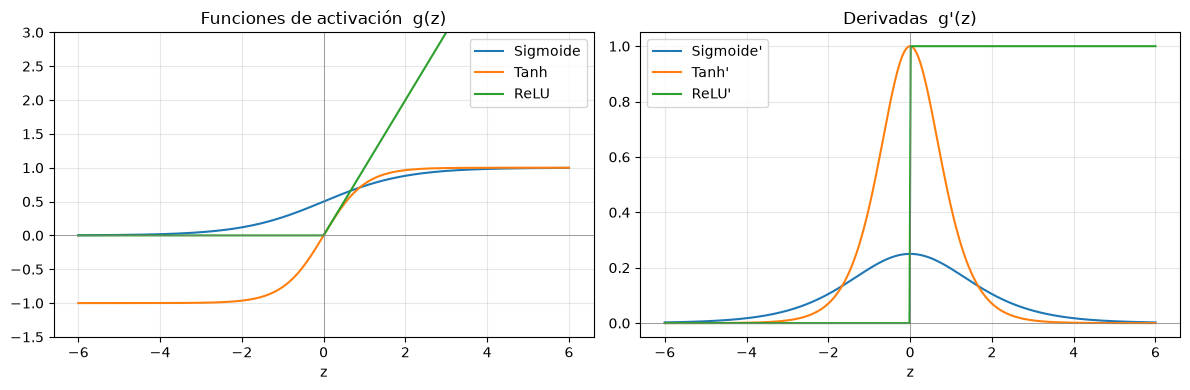

In [2]:
# ---- Funciones de activación y sus derivadas (vectorizadas) ----
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def d_sigmoid(z):
    s = sigmoid(z)
    return s * (1.0 - s)

def tanh(z):
    return np.tanh(z)

def d_tanh(z):
    return 1.0 - np.tanh(z) ** 2

def relu(z):
    return np.maximum(0.0, z)

def d_relu(z):
    return (z > 0).astype(float)

# ---- Visualización ----
z = np.linspace(-6, 6, 400)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, f, df in [("Sigmoide", sigmoid, d_sigmoid),
                    ("Tanh", tanh, d_tanh),
                    ("ReLU", relu, d_relu)]:
    axes[0].plot(z, f(z), label=name)
    axes[1].plot(z, df(z), label=f"{name}'")

axes[0].set_title("Funciones de activación  g(z)")
axes[1].set_title("Derivadas  g'(z)")
for ax in axes:
    ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
    ax.set_xlabel("z"); ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylim(-1.5, 3)
plt.tight_layout(); plt.show()

## 1.4 ¿Por qué la no-linealidad es indispensable?

Supón una red de dos capas **sin** activación (o con $g(z)=z$):

$$a^{[1]} = W^{[1]}x + b^{[1]}, \qquad a^{[2]} = W^{[2]}a^{[1]} + b^{[2]}$$

Sustituyendo:

$$a^{[2]} = W^{[2]}\bigl(W^{[1]}x + b^{[1]}\bigr) + b^{[2]} = \underbrace{(W^{[2]}W^{[1]})}_{W'}\,x + \underbrace{(W^{[2]}b^{[1]} + b^{[2]})}_{b'}$$

¡Es **otra función lineal**! Da igual cuántas capas apilemos: sin no-linealidad, toda la red colapsa a **una sola** transformación lineal y solo podría separar clases con un hiperplano (no puede resolver ni siquiera XOR). Lo comprobamos numéricamente:

In [3]:
rng = np.random.default_rng(0)

# Dos capas lineales (sin activación)
W1, b1 = rng.normal(size=(3, 2)), rng.normal(size=(3, 1))
W2, b2 = rng.normal(size=(1, 3)), rng.normal(size=(1, 1))
x = rng.normal(size=(2, 1))

salida_2_capas = W2 @ (W1 @ x + b1) + b2

# Capa única equivalente
W_eq = W2 @ W1
b_eq = W2 @ b1 + b2
salida_1_capa = W_eq @ x + b_eq

print("Salida con 2 capas lineales :", salida_2_capas.ravel())
print("Salida con 1 capa equivalente:", salida_1_capa.ravel())
print("¿Idénticas?                  :", np.allclose(salida_2_capas, salida_1_capa))

Salida con 2 capas lineales : [-4.61296]
Salida con 1 capa equivalente: [-4.61296]
¿Idénticas?                  : True


## 1.5 Ejemplo numérico manual con **una sola neurona**

Datos:

$$\mathbf{x}=\begin{bmatrix}2\\-1\end{bmatrix},\qquad \mathbf{w}=\begin{bmatrix}0.5\\0.3\end{bmatrix},\qquad b=0.1$$

**Paso 1 · Combinación lineal**

$$z = w_1x_1 + w_2x_2 + b = (0.5)(2) + (0.3)(-1) + 0.1 = 1.0 - 0.3 + 0.1 = \mathbf{0.8}$$

**Paso 2 · Activación** (comparamos las tres):

$$\sigma(0.8)=\frac{1}{1+e^{-0.8}}=\frac{1}{1+0.4493}\approx \mathbf{0.6900}$$

$$\tanh(0.8)\approx \mathbf{0.6640}$$

$$\text{ReLU}(0.8)=\max(0,0.8)=\mathbf{0.8}$$

Y las derivadas en ese punto (nos servirán en el Bloque 5):

$$\sigma'(0.8)=0.6900\,(1-0.6900)\approx 0.2139,\quad \tanh'(0.8)=1-0.6640^2\approx0.5591,\quad \text{ReLU}'(0.8)=1$$

Verificación con código:

In [4]:
x = np.array([2.0, -1.0])
w = np.array([0.5, 0.3])
b = 0.1

z = np.dot(w, x) + b
print(f"z            = {z:.4f}")
print(f"sigmoid(z)   = {sigmoid(z):.4f}   | derivada = {d_sigmoid(z):.4f}")
print(f"tanh(z)      = {tanh(z):.4f}   | derivada = {d_tanh(z):.4f}")
print(f"relu(z)      = {relu(z):.4f}   | derivada = {d_relu(z):.4f}")

z            = 0.8000
sigmoid(z)   = 0.6900   | derivada = 0.2139
tanh(z)      = 0.6640   | derivada = 0.5591
relu(z)      = 0.8000   | derivada = 1.0000


---
# Bloque 2 · Arquitectura y Vectorización

## 2.1 De neuronas a capas

Una **capa** es un conjunto de neuronas que reciben las *mismas* entradas pero tienen *pesos distintos*. Una red neuronal apila capas:

```
  CAPA DE ENTRADA     CAPA OCULTA (l=1)      CAPA DE SALIDA (l=2)
     (n⁰ = 3)            (n¹ = 4)               (n² = 1)

      x₁ ───────┬───▶ (a¹₁) ───╲
         ╲      ├───▶ (a¹₂) ────╲
      x₂ ─╳─────┼───▶ (a¹₃) ─────▶ (a²₁) ──▶ ŷ
         ╱      ├───▶ (a¹₄) ────╱
      x₃ ───────┘                  
         (cada flecha = un peso w)
```

- **Capa de entrada:** no calcula nada; simplemente son los datos $A^{[0]}=X$.
- **Capas ocultas:** extraen representaciones intermedias (*features*) de los datos.
- **Capa de salida:** produce la predicción $\hat y$.

**Notación:** el superíndice $[l]$ indica la capa; $n^{[l]}$ es el número de neuronas de la capa $l$.

> 👉 Justo debajo detallamos qué es exactamente $n^{[0]}$ (el tamaño de la capa de entrada) y qué es $m$ (el número de ejemplos), porque son las dos dimensiones que más se confunden.

### ¿Qué es exactamente $n^{[0]}$?

$n^{[0]}$ es el **número de características de entrada** (*input features*) de **un solo ejemplo**: cuántos números hacen falta para describir una observación antes de que entre en la red.

- Es el tamaño de la **capa 0** (la capa de entrada). Por eso $X=A^{[0]}$ tiene exactamente $n^{[0]}$ **filas**.
- La capa 0 **no tiene neuronas que calculen nada**: no existe $W^{[0]}$, ni $b^{[0]}$, ni activación. Simplemente *contiene* los datos. Las primeras neuronas "de verdad" son las de la capa 1.
- Es la única dimensión que **no elegimos nosotros**: la impone el problema.

$$\underbrace{n^{[0]}}_{\text{lo fijan los datos}}\;\longrightarrow\;\underbrace{n^{[1]},\dots,n^{[L-1]}}_{\text{los eliges tú (hiperparámetros)}}\;\longrightarrow\;\underbrace{n^{[L]}}_{\text{lo fija la tarea}}$$

| Problema | Un ejemplo es… | $n^{[0]}$ |
|---|---|:-:|
| Precio de una casa | (superficie, nº de habitaciones, antigüedad) | $3$ |
| XOR (Bloque 6) | $(x_1,\,x_2)$ | $2$ |
| Dígito escrito a mano (MNIST) | imagen $28\times28$ en grises, aplanada | $784$ |
| Foto en color | $64\times64$ píxeles $\times$ 3 canales (RGB) | $12\,288$ |

**Para qué lo necesitamos:** $n^{[0]}$ fija la forma de la primera matriz de pesos, $W^{[1]}\in\mathbb R^{n^{[1]}\times n^{[0]}}$: cada neurona de la capa 1 necesita **un peso por cada característica**. En el código, `layer_sizes = [n0, n1, ..., nL]`; así, `[2, 4, 1]` significa $n^{[0]}=2,\ n^{[1]}=4,\ n^{[2]}=1$ (ver el diagrama de arriba: $n^{[0]}=3$ entradas $x_1,x_2,x_3$).

### ¿Qué son los ejemplos ($m$)?

Un **ejemplo** (*training example*) es **una observación completa**: lo que entra en la red, $x^{(i)}$, junto con la respuesta correcta, $y^{(i)}$. Y $m$ es **cuántos ejemplos** tenemos.

**Notación — ¡no confundir los dos superíndices!**

| Superíndice | Significa | Ejemplo |
|---|---|---|
| $[l]$ (corchetes) | número de **capa** | $W^{[2]}$ = pesos de la capa 2 |
| $(i)$ (paréntesis) | número de **ejemplo** | $x^{(3)}$ = el tercer ejemplo |
| ambos | capa $l$, ejemplo $i$ | $a^{[2](3)}$ = activación de la capa 2 para el ejemplo 3 |

**Ejemplo concreto.** Queremos predecir el precio de una casa a partir de sus características. Tenemos 4 casas ya vendidas:

| $i$ | superficie (m²) | habitaciones | antigüedad (años) | precio $y^{(i)}$ (k€) |
|:-:|:-:|:-:|:-:|:-:|
| 1 | 50 | 1 | 10 | 150 |
| 2 | 80 | 2 | 5 | 260 |
| 3 | 120 | 3 | 20 | 300 |
| 4 | 65 | 2 | 2 | 230 |

Aquí $n^{[0]}=3$ (tres características) y $m=4$ (cuatro ejemplos). El ejemplo 1 es el vector columna $x^{(1)}=\begin{bmatrix}50\\1\\10\end{bmatrix}$ con etiqueta $y^{(1)}=150$.

Apilamos los ejemplos **como columnas**:

$$X=\begin{bmatrix}x^{(1)}&x^{(2)}&x^{(3)}&x^{(4)}\end{bmatrix}=\begin{bmatrix}50&80&120&65\\1&2&3&2\\10&5&20&2\end{bmatrix}\in\mathbb R^{3\times4},\qquad Y=\begin{bmatrix}150&260&300&230\end{bmatrix}\in\mathbb R^{1\times4}$$

> **Regla mnemotécnica:** *filas = características* ($n^{[0]}$), *columnas = ejemplos* ($m$). (Ojo: pandas y scikit-learn usan la convención contraria, $(m,\,n^{[0]})$; hay que transponer con `X.T`.)

**Idea clave: los parámetros no dependen de $m$.** $W^{[l]}$ y $b^{[l]}$ solo dependen de $n^{[l]}$ y $n^{[l-1]}$. La *misma* red procesa $m=1$ ejemplo (al predecir), $m=4$ (XOR) o $m=60\,000$ (MNIST) sin cambiar un solo parámetro: solo cambia el número de **columnas** de $X$, $Z^{[l]}$ y $A^{[l]}$. Eso es justo lo que hace posible la vectorización. Lo comprobamos:

In [5]:
# Ejemplo: 4 casas, 3 características cada una  ->  n0 = 3, m = 4
X_casas = np.array([[ 50.,  80., 120.,  65.],     # superficie (m²)
                    [  1.,   2.,   3.,   2.],     # habitaciones
                    [ 10.,   5.,  20.,   2.]])    # antigüedad (años)
Y_casas = np.array([[150., 260., 300., 230.]])    # precio (k€)

n0, m_casas = X_casas.shape
print(f"n[0] = {n0} características   |   m = {m_casas} ejemplos")
print("Forma de X:", X_casas.shape, "  Forma de Y:", Y_casas.shape)
print("Ejemplo x^(1) (columna 0):", X_casas[:, 0], "-> como columna:", X_casas[:, [0]].shape)

# Los parámetros NO dependen de m: la misma capa 1 (n1 = 4 neuronas) procesa 1, 4 o 1000 ejemplos
rng = np.random.default_rng(7)
n1 = 4
W1_demo, b1_demo = rng.normal(size=(n1, n0)), np.zeros((n1, 1))
print(f"\nW1 {W1_demo.shape} = (n1, n0)   b1 {b1_demo.shape} = (n1, 1)   <- no cambian con m")
for m_demo in (1, 4, 1000):
    X_demo = rng.normal(size=(n0, m_demo))
    Z_demo = W1_demo @ X_demo + b1_demo
    print(f"  m = {m_demo:>4}:  X {X_demo.shape}  ->  Z1 {Z_demo.shape}")

n[0] = 3 características   |   m = 4 ejemplos
Forma de X: (3, 4)   Forma de Y: (1, 4)
Ejemplo x^(1) (columna 0): [50.  1. 10.] -> como columna: (3, 1)

W1 (4, 3) = (n1, n0)   b1 (4, 1) = (n1, 1)   <- no cambian con m
  m =    1:  X (3, 1)  ->  Z1 (4, 1)
  m =    4:  X (3, 4)  ->  Z1 (4, 4)
  m = 1000:  X (3, 1000)  ->  Z1 (4, 1000)


## 2.2 Vectorización: de una neurona a una capa completa

Si la capa $l$ tiene $n^{[l]}$ neuronas y la capa anterior $n^{[l-1]}$, apilamos los vectores de pesos de cada neurona **como filas** de una matriz:

$$W^{[l]}\in\mathbb{R}^{n^{[l]}\times n^{[l-1]}},\qquad b^{[l]}\in\mathbb{R}^{n^{[l]}\times 1}$$

Para **un** ejemplo de entrenamiento:

$$z^{[l]} = W^{[l]}a^{[l-1]} + b^{[l]},\qquad a^{[l]}=g^{[l]}\bigl(z^{[l]}\bigr)$$

Para **un lote de $m$ ejemplos** colocamos cada ejemplo como **una columna** de $A^{[l-1]}\in\mathbb{R}^{n^{[l-1]}\times m}$:

$$\boxed{Z^{[l]} = W^{[l]}A^{[l-1]} + b^{[l]}}\qquad\qquad A^{[l]} = g^{[l]}\bigl(Z^{[l]}\bigr)$$

(el vector $b^{[l]}$ se *suma a cada columna*: es el *broadcasting* de NumPy).

### Tabla de dimensiones (¡la mejor herramienta anti-bugs!)

| Objeto | Forma |
|---|---|
| Un ejemplo $x^{(i)}$ (una columna de $X$) | $(n^{[0]},\, 1)$ |
| $X = A^{[0]}$ | $(n^{[0]},\, m)$ |
| $W^{[l]}$ | $(n^{[l]},\, n^{[l-1]})$ |
| $b^{[l]}$ | $(n^{[l]},\, 1)$ |
| $Z^{[l]},\,A^{[l]}$ | $(n^{[l]},\, m)$ |
| $Y$ y $\hat Y=A^{[L]}$ | $(n^{[L]},\, m)$ |

Fíjate en que **$m$ solo aparece en los datos y las activaciones**, nunca en $W$ ni en $b$.

La vectorización no solo es más elegante: reemplaza bucles de Python por multiplicaciones matriciales optimizadas en C/BLAS (cientos de veces más rápidas).

In [6]:
# Comprobamos las dimensiones de una red 3 -> 4 -> 1 con un lote de m = 5 ejemplos
rng = np.random.default_rng(1)
m = 5
X  = rng.normal(size=(3, m))              # (n0, m)
W1 = rng.normal(size=(4, 3)); b1 = np.zeros((4, 1))
W2 = rng.normal(size=(1, 4)); b2 = np.zeros((1, 1))

Z1 = W1 @ X + b1          # (4,3)@(3,5) + (4,1)  ->  (4,5)   [broadcasting de b1]
A1 = np.tanh(Z1)
Z2 = W2 @ A1 + b2         # (1,4)@(4,5) + (1,1)  ->  (1,5)
A2 = sigmoid(Z2)

for nombre, arr in [("X", X), ("W1", W1), ("b1", b1), ("Z1", Z1),
                    ("A1", A1), ("W2", W2), ("b2", b2), ("Z2", Z2), ("A2", A2)]:
    print(f"{nombre:>3}: {arr.shape}")

# Vectorizado vs. bucle: mismo resultado
Z1_loop = np.column_stack([W1 @ X[:, [i]] + b1 for i in range(m)])
print("\n¿Z1 vectorizado == Z1 con bucle?", np.allclose(Z1, Z1_loop))

  X: (3, 5)
 W1: (4, 3)
 b1: (4, 1)
 Z1: (4, 5)
 A1: (4, 5)
 W2: (1, 4)
 b2: (1, 1)
 Z2: (1, 5)
 A2: (1, 5)

¿Z1 vectorizado == Z1 con bucle? True


---
# Bloque 3 · Forward Propagation

## 3.1 El flujo de información

*Forward propagation* es simplemente **evaluar la red** de izquierda a derecha: la salida de cada capa es la entrada de la siguiente.

$$A^{[0]}=X\;\xrightarrow{\;W^{[1]},b^{[1]},g^{[1]}\;}\;A^{[1]}\;\xrightarrow{\;W^{[2]},b^{[2]},g^{[2]}\;}\;A^{[2]}=\hat Y$$

Algoritmo general para $l=1,\dots,L$:

1. $Z^{[l]} = W^{[l]}A^{[l-1]}+b^{[l]}$
2. $A^{[l]} = g^{[l]}(Z^{[l]})$

⚠️ **Importante:** hay que **guardar** ($Z^{[l]}$, $A^{[l]}$) de cada capa (*caché*), porque la retropropagación los necesitará.

## 3.2 Ejemplo numérico guiado: red 2 → 2 → 1

```
                  W¹ (2×2)              W² (1×2)
   x₁=1.0 ──┬──▶ ( h₁ ) ──╲
            │ ╲            ╲
            │  ╳            ▶ ( o ) ──▶ ŷ        (y real = 1)
            │ ╱            ╱
   x₂=0.5 ──┴──▶ ( h₂ ) ──╱
```

Usaremos **sigmoide en todas las neuronas**. Parámetros (inventados, solo para ilustrar):

$$x=\begin{bmatrix}1.0\\0.5\end{bmatrix},\quad
W^{[1]}=\begin{bmatrix}0.2&-0.3\\0.4&0.1\end{bmatrix},\quad
b^{[1]}=\begin{bmatrix}0.1\\-0.1\end{bmatrix},\quad
W^{[2]}=\begin{bmatrix}0.3&-0.2\end{bmatrix},\quad
b^{[2]}=0.05,\quad y=1$$

### Capa oculta

$$z^{[1]}_1 = 0.2(1.0) + (-0.3)(0.5) + 0.1 = 0.2-0.15+0.1 = 0.15$$
$$z^{[1]}_2 = 0.4(1.0) + (0.1)(0.5) - 0.1 = 0.4+0.05-0.1 = 0.35$$

$$a^{[1]}_1=\sigma(0.15)=0.53743,\qquad a^{[1]}_2=\sigma(0.35)=0.58662$$

### Capa de salida

$$z^{[2]} = 0.3(0.53743) + (-0.2)(0.58662) + 0.05 = 0.16123 - 0.11732 + 0.05 = 0.09391$$

$$\hat y = a^{[2]}=\sigma(0.09391)=\mathbf{0.52346}$$

La red predice $0.523$ cuando el valor correcto es $1$: ¡hay error! Lo cuantificaremos en el Bloque 4.

In [7]:
# Verificación numérica del ejemplo guiado (columnas = ejemplos)
x  = np.array([[1.0], [0.5]])
y  = np.array([[1.0]])

W1 = np.array([[0.2, -0.3],
               [0.4,  0.1]])
b1 = np.array([[ 0.1],
               [-0.1]])
W2 = np.array([[0.3, -0.2]])
b2 = np.array([[0.05]])

Z1 = W1 @ x + b1
A1 = sigmoid(Z1)
Z2 = W2 @ A1 + b2
A2 = sigmoid(Z2)

print("Z1 =", Z1.ravel())
print("A1 =", A1.ravel())
print("Z2 =", Z2.ravel())
print("ŷ  =", A2.ravel())

Z1 = [0.15 0.35]
A1 = [0.53743 0.58662]
Z2 = [0.09391]
ŷ  = [0.52346]


---
# Bloque 4 · El Error: Funciones de Pérdida y Coste

## 4.1 Intuición

Para *aprender* necesitamos un número que diga **cuán mal** lo hace la red. Ese número es la **pérdida** (*loss*) $\mathcal{L}(\hat y, y)$ para un ejemplo, y el **coste** (*cost*) $J$ es su promedio sobre los $m$ ejemplos:

$$J(W,b)=\frac1m\sum_{i=1}^{m}\mathcal{L}\bigl(\hat y^{(i)},y^{(i)}\bigr)$$

Requisitos de una buena pérdida: ser $\ge0$, valer $0$ solo si $\hat y=y$, y ser **diferenciable** (para poder calcular gradientes).

### ¿Qué dimensiones tienen $\mathcal L$ y $J$?

> **Aviso de notación:** $\mathcal L$ (caligráfica) es la **pérdida**; $L$ (recta) es el **número de capas** de la red. Son cosas distintas.

La pérdida de un ejemplo es **un único número real** (un escalar), por grande que sea la red:

$$\mathcal L:\ \mathbb R^{n^{[L]}}\times\mathbb R^{n^{[L]}}\longrightarrow\mathbb R,\qquad(\hat y,\;y)\longmapsto\mathcal L(\hat y,y)$$

Entran la predicción $\hat y$ y la etiqueta $y$ (ambas con forma $(n^{[L]},1)$) y sale **un solo número** que resume cuánto se ha equivocado la red.

| Situación | $\hat y,\ y$ | $\mathcal L$ |
|---|:-:|---|
| Clasificación binaria (XOR) | $(1,1)$ | escalar: $-\bigl[y\log\hat y+(1-y)\log(1-\hat y)\bigr]$ |
| Regresión con 2 salidas | $(2,1)$ | **sigue siendo un escalar**: se suman las salidas, p. ej. $\tfrac12\sum_{k=1}^{2}(\hat y_k-y_k)^2$ |
| Calcular $\mathcal L$ de los $m$ ejemplos a la vez | $(n^{[L]},m)$ | **$m$ escalares**: un vector fila de forma $(1,m)$ |
| Coste $J$ (la media de lo anterior) | — | escalar |

**Ejemplo con 2 salidas:** $\hat y=\begin{bmatrix}2.5\\1.0\end{bmatrix}$, $y=\begin{bmatrix}3.0\\0.0\end{bmatrix}$ $\;\Rightarrow\;\mathcal L=\tfrac12\bigl[(2.5-3)^2+(1.0-0)^2\bigr]=\tfrac12(0.25+1)=\mathbf{0.625}$. Dos salidas, pero un solo número.

**¿Por qué tiene que ser un escalar?**

1. **Para poder comparar.** "Esta red es mejor que aquella" solo tiene sentido si cada una recibe *una* nota; los vectores no tienen un orden natural.
2. **Porque el gradiente de un escalar respecto de un array tiene la forma de ese array** (lo vemos en §5.2): $\partial\mathcal L/\partial W$ es una matriz de la misma forma que $W$, y por eso podemos actualizar $W:=W-\alpha\,dW$ entrada a entrada.
3. La retropropagación arranca de **una única "semilla"**: la derivada de *un* número respecto de la salida de la red.

### ¿De qué parámetros depende $\mathcal L$?

Por definición, $\mathcal L$ recibe solo $\hat y$ e $y$. Pero conviene separar **qué es constante y qué es variable** durante el entrenamiento:

| Elemento | Papel | ¿Lo derivamos? |
|---|---|:-:|
| $x,\ y$ (el ejemplo) | **datos**: fijos | No |
| $\hat y=a^{[L]}$ | no es libre: **lo calcula la red** a partir de $x$ y de los parámetros | — |
| $\theta=\{W^{[1]},b^{[1]},\dots,W^{[L]},b^{[L]}\}$ | **parámetros**: lo único que podemos mover | **Sí** |
| $\alpha$, nº de capas, $n^{[l]}$, activaciones | hiperparámetros: los fijamos nosotros | No |

Como $\hat y=f(x;\theta)$, **para un ejemplo fijo $(x,y)$ la pérdida es una función de *todos* los parámetros de *todas* las capas**:

$$\mathcal L=\mathcal L\bigl(W^{[1]},b^{[1]},\dots,W^{[L]},b^{[L]}\bigr)$$

La dependencia es **indirecta**: cada parámetro influye en $\mathcal L$ solo a través del camino que lo lleva hasta la salida (la cadena del grafo computacional de §5.2). Para la red $2\to2\to1$ del Bloque 3 con MSE, escrita de dentro hacia fuera:

$$\mathcal L\bigl(W^{[1]},b^{[1]},W^{[2]},b^{[2]}\bigr)=\tfrac12\Bigl(\sigma\bigl(W^{[2]}\,\sigma(W^{[1]}x+b^{[1]})+b^{[2]}\bigr)-y\Bigr)^2$$

Cuántas variables tiene esa función ($P$ = número total de parámetros):

$$P=\sum_{l=1}^{L}\bigl(\underbrace{n^{[l]}\,n^{[l-1]}}_{W^{[l]}}+\underbrace{n^{[l]}}_{b^{[l]}}\bigr)$$

| Red | Cálculo | $P$ |
|---|---|:-:|
| $2\to2\to1$ (Bloque 3) | $(2\cdot2+2)+(1\cdot2+1)=6+3$ | $9$ |
| $2\to4\to1$ (XOR) | $(4\cdot2+4)+(1\cdot4+1)=12+5$ | $17$ |
| $3\to5\to4\to1$ | $(15+5)+(20+4)+(4+1)$ | $49$ |
| $784\to128\to10$ (MNIST pequeña) | $(100\,352+128)+(1\,280+10)$ | $101\,770$ |

Así, $\mathcal L$ es una "superficie" en un espacio de $P$ dimensiones y su gradiente $\nabla\mathcal L$ tiene **$P$ componentes**, una por parámetro. Lo comprobamos con la red $2\to2\to1$: metemos los 9 parámetros en un vector $\theta$, obtenemos **un** número, y medimos cuánto cambia $\mathcal L$ al mover cada parámetro una cantidad minúscula.

In [8]:
# ℒ como función de los parámetros: entran P = 9 números, sale 1 número
x_c, y_c = np.array([[1.0], [0.5]]), 1.0           # el ejemplo (x, y) es FIJO: son datos, no se derivan
theta = np.array([0.2, -0.3, 0.4, 0.1,             # W1 (2x2, aplanada)
                  0.1, -0.1,                       # b1 (2)
                  0.3, -0.2,                       # W2 (1x2)
                  0.05])                           # b2 (1)
nombres = ["W1[0,0]", "W1[0,1]", "W1[1,0]", "W1[1,1]", "b1[0]", "b1[1]", "W2[0,0]", "W2[0,1]", "b2[0]"]

def loss_theta(t):
    """ℒ(θ): desempaqueta θ en (W1, b1, W2, b2), hace el forward y devuelve el ESCALAR ℒ (MSE)."""
    W1_, b1_ = t[0:4].reshape(2, 2), t[4:6].reshape(2, 1)
    W2_, b2_ = t[6:8].reshape(1, 2), t[8:9].reshape(1, 1)
    y_hat = sigmoid(W2_ @ sigmoid(W1_ @ x_c + b1_) + b2_)
    return 0.5 * ((y_hat - y_c) ** 2).item()

print(f"P = {theta.size} parámetros  ->  ℒ(θ) = {loss_theta(theta):.5f}   (un único número)\n")

eps = 1e-6
print("¿Cuánto cambia ℒ al mover SOLO un parámetro?   ∂ℒ/∂θₖ ≈ [ℒ(θ+ε·eₖ) − ℒ(θ−ε·eₖ)] / 2ε")
for k, nombre in enumerate(nombres):
    e_k = np.zeros_like(theta); e_k[k] = eps
    g_k = (loss_theta(theta + e_k) - loss_theta(theta - e_k)) / (2 * eps)
    print(f"  {nombre:>8}: {g_k:+.5f}")
print("\nNueve parámetros -> nueve derivadas parciales. Son exactamente los números que\ncalcularemos con backpropagation a mano en §5.4.")

P = 9 parámetros  ->  ℒ(θ) = 0.11355   (un único número)

¿Cuánto cambia ℒ al mover SOLO un parámetro?   ∂ℒ/∂θₖ ≈ [ℒ(θ+ε·eₖ) − ℒ(θ−ε·eₖ)] / 2ε
   W1[0,0]: -0.00887
   W1[0,1]: -0.00443
   W1[1,0]: +0.00577
   W1[1,1]: +0.00288
     b1[0]: -0.00887
     b1[1]: +0.00577
   W2[0,0]: -0.06389
   W2[0,1]: -0.06973
     b2[0]: -0.11887

Nueve parámetros -> nueve derivadas parciales. Son exactamente los números que
calcularemos con backpropagation a mano en §5.4.


### Diferencia esencial entre $\mathcal L$ y $J$ al hacer cálculos

Recordemos la relación: $J(\theta)=\dfrac1m\sum_{i=1}^{m}\mathcal L\bigl(\hat y^{(i)},y^{(i)}\bigr)$.

> **Analogía:** $\mathcal L$ es la nota de **una pregunta** del examen; $J$ es la **nota media** del examen completo.

| | $\mathcal L$ (pérdida) | $J$ (coste) |
|---|---|---|
| Qué mide | el error en **un** ejemplo | el error **medio** sobre los $m$ ejemplos (o sobre un mini-lote) |
| Entradas | $(\hat y^{(i)},y^{(i)})$ de un ejemplo | todos los ejemplos |
| Forma | escalar | escalar |
| Depende de $m$ | no | sí (es una media) |
| Sus derivadas | $dz,\ da$ (activaciones): **una por ejemplo**, sin $\tfrac1m$ | $dW,\ db$ (parámetros): **promedio** de los ejemplos, con $\tfrac1m$ |
| Para qué se usa | *derivar*: la cadena de §5.3 se escribe para un ejemplo | *informar* (curva de pérdida) y *minimizar* (descenso del gradiente) |

**La regla que lo conecta todo** es que la derivada es lineal: *la derivada de una media es la media de las derivadas*.

$$\boxed{\frac{\partial J}{\partial\theta}=\frac1m\sum_{i=1}^{m}\frac{\partial\mathcal L^{(i)}}{\partial\theta}}$$

Por eso el procedimiento es siempre: **(1)** derivar $\mathcal L$ para *un* ejemplo (fácil: es una cadena de funciones) y **(2)** promediar.

**¿Dónde aparece el $\tfrac1m$ en el código?** Solo en `dW` y `db`, nunca en `dZ`:

- $Z^{[l]},\,A^{[l]},\,dZ^{[l]}$ son **por ejemplo**: la columna $i$ solo depende del ejemplo $i$. Cada columna de $dZ$ es $\partial\mathcal L^{(i)}/\partial z^{(i)}$, sin dividir.
- $W^{[l]},\,b^{[l]}$ están **compartidos** por todos los ejemplos, así que su gradiente recibe una contribución de *cada* ejemplo: se suman y se divide entre $m$.

(En §5.4, con $m=1$, resulta $J=\mathcal L$: por eso allí no aparece ningún $\tfrac1m$.)

**Ejemplo con $m=3$** (entropía cruzada). La red predice $\hat y=[0.9,\ 0.2,\ 0.6]$ y las etiquetas son $y=[1,\ 0,\ 0]$:

| ejemplo $i$ | $\hat y^{(i)}$ | $y^{(i)}$ | $\mathcal L^{(i)}=-\bigl[y\log\hat y+(1-y)\log(1-\hat y)\bigr]$ | $dz^{(i)}=\hat y-y$ |
|:-:|:-:|:-:|:-:|:-:|
| 1 | 0.9 | 1 | $-\log0.9=0.10536$ | $-0.1$ |
| 2 | 0.2 | 0 | $-\log0.8=0.22314$ | $+0.2$ |
| 3 | 0.6 | 0 | $-\log0.4=0.91629$ | $+0.6$ |

$$J=\frac{0.10536+0.22314+0.91629}{3}=\mathbf{0.41493},\qquad\frac{\partial J}{\partial b^{[L]}}=\frac{(-0.1)+0.2+0.6}{3}=\mathbf{0.2333}$$

Cada $\mathcal L^{(i)}$ nos dice **qué ejemplo lo hace peor** (el 3); $J$ da **un único número** para decidir si la red mejora tras actualizar los parámetros. Y el gradiente positivo indica que, en promedio, hay que **bajar** $b^{[L]}$ (el ejemplo 3, con $y=0$ pero $\hat y=0.6$, pesa más que el 1).

**Otras diferencias prácticas**

- Si usáramos la **suma** en vez de la media, el gradiente crecería con $m$ y habría que reajustar $\alpha$ cada vez que cambiara el tamaño del dataset. La media hace que $J$ y su gradiente sean **independientes de $m$**.
- $J$ puede incluir términos que **no son una media de pérdidas por ejemplo**, p. ej. la regularización $L_2$: $J=\frac1m\sum_i\mathcal L^{(i)}+\frac{\lambda}{2m}\sum_l\lVert W^{[l]}\rVert^2$ (ejercicio 3 del final). Ese término depende solo de los parámetros, no de ningún ejemplo concreto.
- Con **mini-lotes**, $J$ se calcula con un subconjunto de $m_b$ ejemplos: es una estimación ruidosa del $J$ completo.

In [9]:
# ℒ por ejemplo vs. J: formas y relación  (entropía cruzada, m = 3)
y_hat_b  = np.array([[0.9, 0.2, 0.6]])              # (n_L, m) = (1, 3)
y_true_b = np.array([[1.0, 0.0, 0.0]])
m_b = y_true_b.shape[1]

L_i = -(y_true_b * np.log(y_hat_b) + (1 - y_true_b) * np.log(1 - y_hat_b))   # ℒ⁽ⁱ⁾ de cada ejemplo
J_b = L_i.mean()                                                              # J = (1/m) Σ ℒ⁽ⁱ⁾

print("ℒ por ejemplo:", L_i.round(5), "  forma:", L_i.shape, " -> m escalares")
print("J            :", round(J_b, 5), "  forma:", np.shape(J_b), "-> un escalar")

# Gradiente respecto del sesgo de salida b:  ∂J/∂b = (1/m) Σ dz⁽ⁱ⁾,  con dz⁽ⁱ⁾ = ŷ⁽ⁱ⁾ − y⁽ⁱ⁾
dz_b = y_hat_b - y_true_b                          # una por ejemplo, SIN 1/m
print("\ndz por ejemplo (∂ℒ⁽ⁱ⁾/∂z⁽ⁱ⁾):", dz_b.ravel())
print("∂J/∂b = media de dz        :", round(dz_b.mean().item(), 5))

# Comprobación numérica derivando J(b) directamente (z = logit(ŷ); b desplaza todos los z por igual)
z_logit = np.log(y_hat_b / (1 - y_hat_b))
def J_de_b(b):
    p = sigmoid(z_logit + b)
    return (-(y_true_b * np.log(p) + (1 - y_true_b) * np.log(1 - p))).mean()
h = 1e-6
print("∂J/∂b (derivada numérica)  :", round((J_de_b(h) - J_de_b(-h)) / (2 * h), 5))

ℒ por ejemplo: [[0.10536 0.22314 0.91629]]   forma: (1, 3)  -> m escalares
J            : 0.41493   forma: () -> un escalar

dz por ejemplo (∂ℒ⁽ⁱ⁾/∂z⁽ⁱ⁾): [-0.1  0.2  0.6]
∂J/∂b = media de dz        : 0.23333
∂J/∂b (derivada numérica)  : 0.23333


## 4.2 Error Cuadrático Medio (MSE)

$$\mathcal{L}_{MSE}=\tfrac12(\hat y-y)^2\qquad\Rightarrow\qquad J_{MSE}=\frac{1}{2m}\sum_{i=1}^m(\hat y^{(i)}-y^{(i)})^2$$

(el factor $\tfrac12$ es una conveniencia: al derivar, cancela el 2). Derivada: $\dfrac{\partial\mathcal L}{\partial\hat y}=\hat y-y$.

**Justificación probabilística.** Supón que el mundo genera los datos como $y=f(x)+\varepsilon$ con ruido gaussiano $\varepsilon\sim\mathcal N(0,\sigma^2)$. Entonces la verosimilitud de una observación es

$$p(y\mid x)=\frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\Bigl(-\frac{(y-\hat y)^2}{2\sigma^2}\Bigr)$$

Maximizar la verosimilitud equivale a minimizar $-\log p$:

$$-\log p(y\mid x)=\frac{(y-\hat y)^2}{2\sigma^2}+\text{cte}$$

→ **MSE es la estimación por máxima verosimilitud bajo ruido gaussiano.** Ideal para **regresión**.

## 4.3 Entropía Cruzada Binaria (Cross-Entropy)

Para clasificación binaria, $y\in\{0,1\}$ y $\hat y\in(0,1)$ se interpreta como $P(y=1\mid x)$. Es una distribución de Bernoulli:

$$p(y\mid x)=\hat y^{\,y}(1-\hat y)^{1-y}$$

Tomando $-\log$:

$$\boxed{\mathcal{L}_{CE}=-\bigl[\,y\log\hat y+(1-y)\log(1-\hat y)\,\bigr]}$$

**Intuición:** si $y=1$ la pérdida es $-\log\hat y$: vale $0$ cuando $\hat y=1$ y tiende a $+\infty$ cuando $\hat y\to0$. Castiga *enormemente* estar muy seguro y equivocarse.

## 4.4 ¿Por qué CE en clasificación y no MSE?

Con salida sigmoide $\hat y=\sigma(z)$:

- **MSE:** $\dfrac{\partial\mathcal L}{\partial z}=(\hat y-y)\,\hat y(1-\hat y)$ → si la red está muy equivocada **pero saturada** ($\hat y\approx0$ con $y=1$), el factor $\hat y(1-\hat y)\approx0$ y el gradiente casi desaparece: aprendizaje lentísimo.
- **CE:** $\dfrac{\partial\mathcal L}{\partial \hat y}=-\dfrac{y}{\hat y}+\dfrac{1-y}{1-\hat y}=\dfrac{\hat y-y}{\hat y(1-\hat y)}$, y al multiplicar por $\sigma'(z)=\hat y(1-\hat y)$:

$$\boxed{\frac{\partial\mathcal L_{CE}}{\partial z}=\hat y-y}$$

El factor de saturación **se cancela**: cuanto mayor el error, mayor el gradiente. Es la combinación natural *sigmoide + entropía cruzada*.

## 4.5 Ejemplo numérico (continuación del Bloque 3)

Con $\hat y=0.52346$ y $y=1$:

$$\mathcal L_{MSE}=\tfrac12(0.52346-1)^2=\tfrac12(0.22710)=\mathbf{0.11355}$$
$$\mathcal L_{CE}=-\log(0.52346)=\mathbf{0.64730}$$

MSE  = 0.11355
BCE  = 0.64730


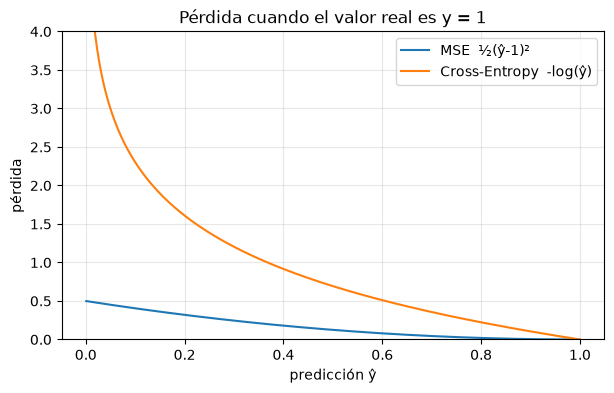

In [10]:
def mse(y_hat, y):
    """Coste MSE con factor 1/2: J = 1/(2m) * sum (y_hat - y)^2"""
    m = y.shape[1]
    return np.sum((y_hat - y) ** 2) / (2 * m)

def bce(y_hat, y, eps=1e-12):
    """Coste de entropía cruzada binaria. 'eps' evita log(0)."""
    m = y.shape[1]
    y_hat = np.clip(y_hat, eps, 1 - eps)
    return -np.sum(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat)) / m

print(f"MSE  = {mse(A2, y):.5f}")
print(f"BCE  = {bce(A2, y):.5f}")

# --- Visualización: pérdida vs predicción cuando y = 1 ---
yh = np.linspace(0.001, 0.999, 500)
plt.plot(yh, 0.5 * (yh - 1) ** 2, label="MSE  ½(ŷ-1)²")
plt.plot(yh, -np.log(yh),         label="Cross-Entropy  -log(ŷ)")
plt.title("Pérdida cuando el valor real es y = 1")
plt.xlabel("predicción ŷ"); plt.ylabel("pérdida"); plt.ylim(0, 4)
plt.legend(); plt.grid(alpha=0.3); plt.show()

---
# Bloque 5 · Backpropagation y Descenso del Gradiente

## 5.1 Descenso del gradiente: la idea

$J(W,b)$ es una "superficie" en el espacio de parámetros. El gradiente $\nabla J$ apunta hacia donde $J$ **crece** más rápido; por tanto avanzamos en sentido **contrario**:

$$\boxed{W^{[l]} := W^{[l]}-\alpha\,\frac{\partial J}{\partial W^{[l]}}\qquad b^{[l]} := b^{[l]}-\alpha\,\frac{\partial J}{\partial b^{[l]}}}$$

$\alpha>0$ es la **tasa de aprendizaje** (*learning rate*): demasiado grande → divergencia; demasiado pequeña → lentitud.

```
   J
   │\                      
   │ \        ← paso: -α·∇J
   │  \__                  
   │     \__    ●  ← mínimo
   └──────────────────── W
```

La pregunta clave: **¿cómo calculamos $\partial J/\partial W^{[l]}$ para *todas* las capas de forma eficiente?** Respuesta: la regla de la cadena aplicada de atrás hacia delante = **backpropagation**.

## 5.2 La Regla de la Cadena

Si $y=f(u)$ y $u=g(x)$, entonces

$$\frac{dy}{dx}=\frac{dy}{du}\cdot\frac{du}{dx}$$

**Visualización como grafo computacional.** Nuestra red es una cadena de operaciones:

```
  W¹,b¹        W²,b²
    │            │
    ▼            ▼
 x ─▶ [z¹] ─▶ [a¹] ─▶ [z²] ─▶ [a²=ŷ] ─▶ [ L ]
       ·σ       ·σ              
 
 FORWARD  ─────────────────────────────────────▶
 BACKWARD ◀─────────────────────────────────────
   ∂L/∂W¹ = ∂L/∂a² · ∂a²/∂z² · ∂z²/∂a¹ · ∂a¹/∂z¹ · ∂z¹/∂W¹
```

Para conocer cómo afecta un peso de la primera capa a la pérdida, **multiplicamos las sensibilidades de cada eslabón** del camino. La clave computacional: los factores del final de la cadena se **reutilizan** para todas las capas anteriores (por eso se propaga un único mensaje, $dZ$, hacia atrás).

### Derivar respecto de un array: ¿qué significa $\dfrac{\partial\mathcal L}{\partial W}$?

La notación $\partial\mathcal L/\partial W$ **no es una división** entre una matriz. Es una forma compacta de decir:

> *calcula la derivada parcial de $\mathcal L$ respecto de **cada entrada** de $W$ y colócalas en un array **con la misma forma que $W$**.*

**Regla.** Si $\mathcal L$ es un **escalar** y $X$ es un array cualquiera (vector, matriz…):

$$\Bigl(\frac{\partial\mathcal L}{\partial X}\Bigr)_{ij}=\frac{\partial\mathcal L}{\partial X_{ij}}\qquad\Longrightarrow\qquad\text{forma}\Bigl(\frac{\partial\mathcal L}{\partial X}\Bigr)=\text{forma}(X)$$

Es el **gradiente**: la derivada de un escalar respecto de varias variables, ordenada igual que esas variables. De ahí una regla anti-bugs de oro: en el código, **`dX.shape == X.shape`** siempre (`dW` como `W`, `db` como `b`, `dZ` como `Z`, `dA` como `A`).

**Por qué tiene que tener la misma forma:** la actualización $W:=W-\alpha\,dW$ se hace entrada a entrada: cada $W_{ij}$ se corrige según *cuánto afecta él solo* a $\mathcal L$.

#### Ejemplo 1 · un vector (la neurona de §1.5)

Tomamos $\mathbf x=\begin{bmatrix}2\\-1\end{bmatrix}$, $\mathbf w=\begin{bmatrix}0.5\\0.3\end{bmatrix}$, $b=0.1$, objetivo $y=1$ y, para simplificar, activación lineal: $\hat y=z=\mathbf w\cdot\mathbf x+b=0.8$. La pérdida es $\mathcal L=\tfrac12(\hat y-y)^2=\tfrac12(-0.2)^2=0.02$.

$\mathcal L$ depende de $w_1$ y de $w_2$ **por separado**, luego hay una derivada parcial para cada uno (regla de la cadena: $\partial\mathcal L/\partial\hat y=\hat y-y$ y $\partial\hat y/\partial w_j=x_j$):

$$\frac{\partial\mathcal L}{\partial w_1}=(\hat y-y)\,x_1=(-0.2)(2)=-0.4,\qquad\frac{\partial\mathcal L}{\partial w_2}=(\hat y-y)\,x_2=(-0.2)(-1)=+0.2$$

$$\frac{\partial\mathcal L}{\partial\mathbf w}=\begin{bmatrix}-0.4\\+0.2\end{bmatrix}\ \bigl(\text{forma }2\times1\text{, como }\mathbf w\bigr),\qquad\frac{\partial\mathcal L}{\partial b}=\hat y-y=-0.2\ \bigl(\text{forma de }b\bigr)$$

*Lectura:* $w_1$ tiene derivada negativa → **subir** $w_1$ reduce $\mathcal L$ (y mucho, porque $x_1=2$ es grande); $w_2$ tiene derivada positiva → conviene **bajarlo**. Un paso con $\alpha=0.1$ da $\mathbf w:=\begin{bmatrix}0.54\\0.28\end{bmatrix}$, $b:=0.12$, y la nueva predicción es $\hat y=0.92$ con $\mathcal L=0.0032$ (antes $0.02$): ¡ha bajado!

#### Ejemplo 2 · una matriz

Una capa con 2 neuronas y 3 entradas, $z=Wx+b$, y $\mathcal L=\tfrac12\lVert z-y\rVert^2=\tfrac12\sum_i(z_i-y_i)^2$. Aquí $W\in\mathbb R^{2\times3}$, así que $\partial\mathcal L/\partial W$ es una matriz $2\times3$ con **6 derivadas parciales**. Como $z_i$ solo contiene los pesos de la fila $i$ (y $\partial z_i/\partial W_{ij}=x_j$):

$$\frac{\partial\mathcal L}{\partial W_{ij}}=(z_i-y_i)\,x_j\quad\Longrightarrow\quad\frac{\partial\mathcal L}{\partial W}=(z-y)\,x^{T}\qquad(2\times1)(1\times3)=(2\times3)$$

Con $x=\begin{bmatrix}1\\2\\-1\end{bmatrix}$ y $z-y=\begin{bmatrix}0.5\\-1\end{bmatrix}$:

$$\frac{\partial\mathcal L}{\partial W}=\begin{bmatrix}0.5\\-1\end{bmatrix}\begin{bmatrix}1&2&-1\end{bmatrix}=\begin{bmatrix}0.5&1&-0.5\\-1&-2&1\end{bmatrix}$$

Es un **producto exterior**: la entrada $(i,j)$ es "error de la neurona $i$" × "entrada $j$". Este es el patrón de la ecuación de $dW$ en §5.3. Lo verificamos con derivadas numéricas:

> **Ojo:** cuando el numerador *no* es un escalar (p. ej. $\partial A/\partial Z$, un vector respecto de otro vector), la derivada ya no tiene la forma del denominador: es una matriz con *todas* las parejas (salida, entrada), el **jacobiano**. Lo tratamos en §5.3.2.

In [11]:
# ---- Ejemplo 1: neurona lineal (vector w) ----
x_n = np.array([2.0, -1.0]); w_n = np.array([0.5, 0.3]); b_n = 0.1; y_n = 1.0

def L_neurona(w, b):
    return 0.5 * (w @ x_n + b - y_n) ** 2

y_hat_n = w_n @ x_n + b_n
dw_n = (y_hat_n - y_n) * x_n                 # analítico: (ŷ − y)·x   -> misma forma que w
db_n = (y_hat_n - y_n)
print(f"ŷ = {y_hat_n:.2f},   ℒ = {L_neurona(w_n, b_n):.4f}")
print("∂ℒ/∂w analítico:", dw_n, "  forma:", dw_n.shape, "(= forma de w:", w_n.shape, ")")

h = 1e-6                                     # numérico: una derivada parcial por componente
dw_num = np.array([(L_neurona(w_n + h * np.eye(2)[j], b_n) - L_neurona(w_n - h * np.eye(2)[j], b_n)) / (2 * h)
                   for j in range(2)])
print("∂ℒ/∂w numérico :", dw_num.round(5))

alpha_n = 0.1                                # un paso de descenso del gradiente
w_new, b_new = w_n - alpha_n * dw_n, b_n - alpha_n * db_n
print(f"Tras un paso (α = {alpha_n}): w = {w_new}, b = {b_new:.2f},  ℒ = {L_neurona(w_new, b_new):.4f}  (antes {L_neurona(w_n, b_n):.4f})")

# ---- Ejemplo 2: matriz W (2x3) ----
W_m = np.array([[0.2, -0.1, 0.4], [0.3, 0.5, -0.2]]); b_m = np.array([0.1, -0.1]); x_m = np.array([1.0, 2.0, -1.0])
z_m = W_m @ x_m + b_m
y_m = z_m - np.array([0.5, -1.0])            # elegimos y para que z − y = [0.5, −1]

def L_capa(W):
    return 0.5 * np.sum((W @ x_m + b_m - y_m) ** 2)

dW_m = np.outer(z_m - y_m, x_m)              # (z − y) xᵀ  (producto exterior)
dW_num = np.zeros_like(W_m)
for idx in np.ndindex(W_m.shape):            # 6 derivadas parciales, una por entrada de W
    E = np.zeros_like(W_m); E[idx] = h
    dW_num[idx] = (L_capa(W_m + E) - L_capa(W_m - E)) / (2 * h)

print("\n∂ℒ/∂W analítico (producto exterior):\n", dW_m)
print("forma:", dW_m.shape, "= forma de W:", W_m.shape)
print("¿coincide con la derivada numérica?", np.allclose(dW_m, dW_num, atol=1e-6))

ŷ = 0.80,   ℒ = 0.0200
∂ℒ/∂w analítico: [-0.4  0.2]   forma: (2,) (= forma de w: (2,) )
∂ℒ/∂w numérico : [-0.4  0.2]
Tras un paso (α = 0.1): w = [0.54 0.28], b = 0.12,  ℒ = 0.0032  (antes 0.0200)

∂ℒ/∂W analítico (producto exterior):
 [[ 0.5  1.  -0.5]
 [-1.  -2.   1. ]]
forma: (2, 3) = forma de W: (2, 3)
¿coincide con la derivada numérica? True


## 5.3 Derivación paso a paso (caso general)

Vamos a **derivar** (no solo enunciar) las ecuaciones de la retropropagación, siguiendo el camino habitual del notebook: intuición → ecuación → ejemplo → código.

### 5.3.0 Calentamiento: la cadena en una red $1\to1\to1$

Antes de usar matrices, veamos la regla de la cadena en su versión más simple: una neurona por capa, sigmoide en ambas y MSE:

$$z^{[1]}=w^{[1]}x+b^{[1]},\quad a^{[1]}=\sigma(z^{[1]}),\quad z^{[2]}=w^{[2]}a^{[1]}+b^{[2]},\quad a^{[2]}=\sigma(z^{[2]}),\quad\mathcal L=\tfrac12(a^{[2]}-y)^2$$

Para saber cómo afecta $w^{[1]}$ a $\mathcal L$ recorremos el camino **hacia atrás**, multiplicando una derivada local por eslabón:

$$\frac{\partial\mathcal L}{\partial w^{[1]}}=\underbrace{(a^{[2]}-y)}_{\partial\mathcal L/\partial a^{[2]}}\cdot\underbrace{a^{[2]}(1-a^{[2]})}_{\partial a^{[2]}/\partial z^{[2]}}\cdot\underbrace{w^{[2]}}_{\partial z^{[2]}/\partial a^{[1]}}\cdot\underbrace{a^{[1]}(1-a^{[1]})}_{\partial a^{[1]}/\partial z^{[1]}}\cdot\underbrace{x}_{\partial z^{[1]}/\partial w^{[1]}}$$

**Números:** $x=1,\ w^{[1]}=0.5,\ b^{[1]}=0.1,\ w^{[2]}=-0.4,\ b^{[2]}=0.2,\ y=1$.

*Forward:* $z^{[1]}=0.6,\ a^{[1]}=0.64566,\ z^{[2]}=-0.05826,\ a^{[2]}=0.48544,\ \mathcal L=0.13239$.

*Backward* (cada línea reutiliza la anterior):

| Paso | Cálculo | Valor |
|---|---|:-:|
| $dz^{[2]}=\partial\mathcal L/\partial z^{[2]}$ | $(a^{[2]}-y)\,a^{[2]}(1-a^{[2]})=(-0.51456)(0.24979)$ | $-0.12853$ |
| $dw^{[2]}$ | $dz^{[2]}\,a^{[1]}=(-0.12853)(0.64566)$ | $-0.08299$ |
| $da^{[1]}$ | $w^{[2]}\,dz^{[2]}=(-0.4)(-0.12853)$ | $+0.05141$ |
| $dz^{[1]}$ | $da^{[1]}\,a^{[1]}(1-a^{[1]})=(0.05141)(0.22878)$ | $+0.01176$ |
| $dw^{[1]}$ | $dz^{[1]}\,x=(0.01176)(1)$ | $+0.01176$ |

(Y los sesgos cumplen $db^{[l]}=dz^{[l]}$.) Observa que **$dz^{[2]}$ aparece en el cálculo de todo lo que hay detrás**: se calcula una sola vez y se reutiliza. Esa reutilización es lo que hace eficiente a la retropropagación. Todo lo que sigue es esta misma película, con vectores y matrices en lugar de escalares. Comprobémoslo:

In [12]:
# Red 1-1-1: backprop a mano (escalares) vs. derivada numérica
x1, y1 = 1.0, 1.0
p = dict(w1=0.5, b1=0.1, w2=-0.4, b2=0.2)

def forward_111(p):
    z1 = p["w1"] * x1 + p["b1"]; a1 = sigmoid(z1)
    z2 = p["w2"] * a1 + p["b2"]; a2 = sigmoid(z2)
    return z1, a1, z2, a2, 0.5 * (a2 - y1) ** 2

z1, a1, z2, a2, L1 = forward_111(p)
print(f"z1={z1:.5f}  a1={a1:.5f}  z2={z2:.5f}  a2={a2:.5f}  ℒ={L1:.5f}\n")

dz2 = (a2 - y1) * a2 * (1 - a2)      # ∂ℒ/∂z2
dw2 = dz2 * a1;  db2 = dz2
da1 = p["w2"] * dz2                  # ∂ℒ/∂a1
dz1 = da1 * a1 * (1 - a1)            # ∂ℒ/∂z1
dw1 = dz1 * x1;  db1 = dz1
analitico = dict(w1=dw1, b1=db1, w2=dw2, b2=db2)
print(f"dz2={dz2:+.5f}   da1={da1:+.5f}   dz1={dz1:+.5f}\n")

h = 1e-6
for k in p:
    pp, pm = dict(p), dict(p); pp[k] += h; pm[k] -= h
    num = (forward_111(pp)[-1] - forward_111(pm)[-1]) / (2 * h)
    print(f"∂ℒ/∂{k}:  backprop = {analitico[k]:+.5f}   numérico = {num:+.5f}")

z1=0.60000  a1=0.64566  z2=-0.05826  a2=0.48544  ℒ=0.13239

dz2=-0.12853   da1=+0.05141   dz1=+0.01176

∂ℒ/∂w1:  backprop = +0.01176   numérico = +0.01176
∂ℒ/∂b1:  backprop = +0.01176   numérico = +0.01176
∂ℒ/∂w2:  backprop = -0.08299   numérico = -0.08299
∂ℒ/∂b2:  backprop = -0.12853   numérico = -0.12853


### 5.3.1 Notación y convenios

Red de $L$ capas y **un ejemplo** $(x,y)$:

$$a^{[0]}=x,\qquad z^{[l]}=W^{[l]}a^{[l-1]}+b^{[l]},\qquad a^{[l]}=g^{[l]}\bigl(z^{[l]}\bigr)\quad(l=1,\dots,L),\qquad\hat y=a^{[L]},\qquad\mathcal L=\mathcal L(a^{[L]},y)$$

**Convenio:** para cualquier variable $v$ escribimos $dv$ para su derivada y recordamos que **tiene la forma de $v$** (§5.2).

- $dz^{[l]},\,da^{[l]}$ son derivadas de la **pérdida $\mathcal L$** (de un ejemplo).
- $dW^{[l]},\,db^{[l]}$ son derivadas del **coste $J$** (ya promediadas sobre el lote), que es lo que usa el descenso del gradiente. Es la diferencia entre $\mathcal L$ y $J$ de §4.1: el $\tfrac1m$ solo aparece aquí.

**Idea clave — el "cuello de botella".** $W^{[l]}$ y $b^{[l]}$ solo pueden influir en $\mathcal L$ **a través de $z^{[l]}$**: no hay otro camino. Por tanto, si conocemos $dz^{[l]}=\partial\mathcal L/\partial z^{[l]}$, los gradientes de los parámetros de esa capa salen con una fórmula local y barata. Todo el algoritmo se reduce a **calcular $dz^{[l]}$ para cada capa, de la última a la primera**:

```
 W[l], b[l] ──▶ z[l] ──▶ a[l] ──▶ z[l+1] ──▶ ... ──▶ ŷ ──▶ ℒ
              ▲
              └─ cuello de botella: todo lo que W[l] y b[l] hacen pasa por z[l]
```

| Objeto | Forma (1 ejemplo) | Forma (lote de $m$) |
|---|:-:|:-:|
| $z^{[l]},\ a^{[l]},\ dz^{[l]},\ da^{[l]}$ | $(n^{[l]},1)$ | $(n^{[l]},m)$ |
| $W^{[l]},\ dW^{[l]}$ | $(n^{[l]},n^{[l-1]})$ | $(n^{[l]},n^{[l-1]})$ |
| $b^{[l]},\ db^{[l]}$ | $(n^{[l]},1)$ | $(n^{[l]},1)$ |

(Los parámetros **no cambian de forma con $m$**; las activaciones sí.)

### 5.3.2 Tres lemas: el eslabón vectorial de la cadena

En §5.3.0 cada eslabón era un número; ahora son vectores. Necesitamos tres hechos.

**Lema 0 (regla de la cadena con vectores).** Si $\mathcal L$ depende de $u\in\mathbb R^p$ solo a través de $v=h(u)\in\mathbb R^q$, entonces

$$\frac{\partial\mathcal L}{\partial u_j}=\sum_{i=1}^{q}\frac{\partial\mathcal L}{\partial v_i}\,\frac{\partial v_i}{\partial u_j}\quad\Longleftrightarrow\quad du=\bigl(\mathrm{Jac}_h\bigr)^{T}dv,\qquad(\mathrm{Jac}_h)_{ij}=\frac{\partial v_i}{\partial u_j}\in\mathbb R^{q\times p}$$

La **suma** aparece porque $u_j$ puede influir en $\mathcal L$ por *varios* caminos a la vez (a través de cada $v_i$) y todos contribuyen. $\mathrm{Jac}_h$ es el **jacobiano**: la matriz con la derivada parcial de cada salida respecto de cada entrada.

**Lema 1 (activación elemento a elemento).** Si $a=g(z)$ se aplica componente a componente, $a_i=g(z_i)$ solo depende de $z_i$:

$$\frac{\partial a_i}{\partial z_k}=\begin{cases}g'(z_i)&i=k\\0&i\neq k\end{cases}\quad\Rightarrow\quad\mathrm{Jac}=\mathrm{diag}\bigl(g'(z)\bigr)\quad\Rightarrow\quad\boxed{dz=g'(z)\odot da}$$

(Multiplicar por una matriz diagonal equivale al producto elemento a elemento $\odot$: **por eso en el código aparece `*` y no `@`**.)

**Lema 2 (capa afín).** Si $z=Wa+b$, entonces $z_i=\sum_jW_{ij}a_j+b_i$ y $\partial z_i/\partial a_j=W_{ij}$:

$$\mathrm{Jac}=W\quad\Rightarrow\quad\boxed{da=W^{T}dz}$$

> ⚠️ El Lema 1 **solo vale para activaciones elemento a elemento** (sigmoide, tanh, ReLU). En *softmax*, cada salida depende de *todos* los $z_k$, el jacobiano **no** es diagonal y hay que usar el producto matricial completo.

### 5.3.3 Paso A · Capa de salida

Con el Lema 1 aplicado a $a^{[L]}=g^{[L]}(z^{[L]})$:

$$dz^{[L]}=\frac{\partial\mathcal L}{\partial a^{[L]}}\odot g'^{[L]}(z^{[L]})$$

El primer factor depende de la pérdida elegida y el segundo de la activación de salida (sigmoide: $g'=\hat y(1-\hat y)$):

| Pérdida | $\partial\mathcal L/\partial\hat y$ | $dz^{[L]}$ (salida sigmoide) |
|---|---|---|
| MSE | $\hat y-y$ | $(\hat y-y)\,\hat y(1-\hat y)$ |
| Entropía cruzada | $-\dfrac{y}{\hat y}+\dfrac{1-y}{1-\hat y}$ | $\hat y-y$ |

**Álgebra de la entropía cruzada** (la cancelación que hace tan natural esta pareja, ver §4.4):

$$dz^{[L]}=\Bigl[-\frac{y}{\hat y}+\frac{1-y}{1-\hat y}\Bigr]\hat y(1-\hat y)=-y(1-\hat y)+(1-y)\hat y=-y+y\hat y+\hat y-y\hat y=\hat y-y$$

### 5.3.4 Paso B · Gradientes de $W^{[l]}$ y $b^{[l]}$ (un ejemplo)

Escribimos $z^{[l]}_k=\sum_jW^{[l]}_{kj}a^{[l-1]}_j+b^{[l]}_k$ y derivamos respecto de **un** peso concreto $W^{[l]}_{ij}$. Solo la ecuación de la neurona $k=i$ contiene ese peso; las demás neuronas no lo ven:

$$\frac{\partial z^{[l]}_k}{\partial W^{[l]}_{ij}}=\delta_{ki}\,a^{[l-1]}_j\qquad\Bigl(\delta_{ki}=1\text{ si }k=i,\ 0\text{ si no}\Bigr),\qquad\frac{\partial z^{[l]}_k}{\partial b^{[l]}_{i}}=\delta_{ki}$$

Por el cuello de botella (Lema 0, sumando sobre todas las $k$):

$$\frac{\partial\mathcal L}{\partial W^{[l]}_{ij}}=\sum_k\frac{\partial\mathcal L}{\partial z^{[l]}_k}\,\frac{\partial z^{[l]}_k}{\partial W^{[l]}_{ij}}=\sum_kdz^{[l]}_k\,\delta_{ki}\,a^{[l-1]}_j=dz^{[l]}_i\,a^{[l-1]}_j,\qquad\frac{\partial\mathcal L}{\partial b^{[l]}_i}=dz^{[l]}_i$$

Colocando estas $n^{[l]}\times n^{[l-1]}$ derivadas en una matriz con la forma de $W^{[l]}$ obtenemos un **producto exterior**:

$$\frac{\partial\mathcal L}{\partial W^{[l]}}=\begin{bmatrix}dz_1a_1&dz_1a_2&\cdots\\dz_2a_1&dz_2a_2&\cdots\\\vdots&\vdots&\ddots\end{bmatrix}=dz^{[l]}\,\bigl(a^{[l-1]}\bigr)^{T}\quad\bigl[(n^{[l]},1)(1,n^{[l-1]})\bigr],\qquad\frac{\partial\mathcal L}{\partial b^{[l]}}=dz^{[l]}$$

**Interpretación:** el gradiente de un peso es **(error de la neurona a la que llega) × (activación de la neurona de la que sale)**. Si la entrada $a_j$ vale $0$ (p. ej. una ReLU apagada), ese peso no recibe gradiente; si el error $dz_i$ vale $0$, tampoco.

### 5.3.5 Del ejemplo al lote

Con $m$ ejemplos, $J=\frac1m\sum_i\mathcal L^{(i)}$ y, por la linealidad de la derivada (§4.1):

$$\frac{\partial J}{\partial W^{[l]}}=\frac1m\sum_{i=1}^{m}dz^{[l](i)}\,\bigl(a^{[l-1](i)}\bigr)^{T}$$

Esa suma de $m$ productos exteriores es **un único producto matricial**. Si $U=[u^{(1)}\cdots u^{(m)}]$ y $V=[v^{(1)}\cdots v^{(m)}]$ tienen los ejemplos en columnas:

$$\bigl(UV^{T}\bigr)_{kj}=\sum_{i=1}^{m}U_{ki}V_{ji}=\sum_{i=1}^{m}u^{(i)}_k\,v^{(i)}_j=\Bigl(\sum_{i}u^{(i)}v^{(i)T}\Bigr)_{kj}$$

Luego, con $dZ^{[l]}\in\mathbb R^{n^{[l]}\times m}$ y $A^{[l-1]}\in\mathbb R^{n^{[l-1]}\times m}$:

$$\boxed{dW^{[l]}=\frac1m\,dZ^{[l]}\,\bigl(A^{[l-1]}\bigr)^{T}\quad\bigl[(n^{[l]},m)(m,n^{[l-1]})=(n^{[l]},n^{[l-1]})\bigr]\qquad db^{[l]}=\frac1m\sum_{i=1}^{m}dz^{[l](i)}}$$

La dimensión $m$ **se contrae** en el producto matricial: multiplicar suma automáticamente sobre los ejemplos. Es el mismo $\tfrac1m\sum$ de §4.1: $W$ y $b$ son compartidos, por eso su gradiente acumula a todos los ejemplos, mientras que $dZ$ y $dA$ (por ejemplo, sin $\tfrac1m$) conservan sus $m$ columnas.

### 5.3.6 Paso C · Propagar el error a la capa anterior

Cada $a^{[l-1]}_j$ **alimenta a todas las neuronas** $i$ de la capa $l$ (abanico de salida), así que su influencia en $\mathcal L$ es la **suma** de todos esos caminos (Lema 0 + Lema 2):

$$da^{[l-1]}_j=\sum_{i=1}^{n^{[l]}}\frac{\partial\mathcal L}{\partial z^{[l]}_i}\frac{\partial z^{[l]}_i}{\partial a^{[l-1]}_j}=\sum_{i}dz^{[l]}_i\,W^{[l]}_{ij}\quad\Longrightarrow\quad da^{[l-1]}=\bigl(W^{[l]}\bigr)^{T}dz^{[l]}$$

Con lote: $dA^{[l-1]}=W^{[l]T}dZ^{[l]}$, de forma $(n^{[l-1]},n^{[l]})(n^{[l]},m)=(n^{[l-1]},m)$. Aquí **no** hay $\tfrac1m$: seguimos en el terreno de $\mathcal L$ por ejemplo.

*Interpretación:* $W^{T}$ **reparte el error hacia atrás** con los mismos pesos que usó el forward para repartir la señal hacia delante.

### 5.3.7 Paso D · Atravesar la activación

Lema 1 en la capa $l-1$:

$$dz^{[l-1]}=da^{[l-1]}\odot g'^{[l-1]}\bigl(z^{[l-1]}\bigr)$$

Y se vuelve al paso B con $l-1$ en lugar de $l$, hasta llegar a la capa 1. Verifiquemos todo el recorrido (A→B→C→D) con la red $2\to2\to1$ y un lote de $m=3$ ejemplos, comprobando además lo dicho en §4.1 y §5.3.5: el gradiente de $J$ es la **media** de los gradientes por ejemplo.

In [13]:
# Verificación: media de gradientes por ejemplo == gradiente vectorizado de J == derivada numérica
# Red 2-2-1 del Bloque 3, entropía cruzada, lote de m = 3 ejemplos
W1_c = np.array([[0.2, -0.3], [0.4, 0.1]]); b1_c = np.array([[0.1], [-0.1]])
W2_c = np.array([[0.3, -0.2]]);             b2_c = np.array([[0.05]])
rng = np.random.default_rng(5)
X3 = rng.normal(size=(2, 3)); Y3 = np.array([[1.0, 0.0, 1.0]])

def fwd(X):
    Z1 = W1_c @ X + b1_c; A1 = sigmoid(Z1)
    Z2 = W2_c @ A1 + b2_c; A2 = sigmoid(Z2)
    return Z1, A1, Z2, A2

def grads(X, Y):
    """Ecuaciones A-D. dW y db se promedian sobre las m columnas de X."""
    Z1, A1, Z2, A2 = fwd(X); m = X.shape[1]
    dZ2 = A2 - Y                                                      # paso A (CE + sigmoide)   (1, m)
    dW2 = dZ2 @ A1.T / m;  db2 = dZ2.sum(axis=1, keepdims=True) / m   # paso B
    dZ1 = (W2_c.T @ dZ2) * A1 * (1 - A1)                              # pasos C y D              (2, m)
    dW1 = dZ1 @ X.T / m;   db1 = dZ1.sum(axis=1, keepdims=True) / m   # paso B
    return dW1, db1, dW2, db2

# (a) Vectorizado: las 3 columnas de golpe
vec = grads(X3, Y3)

# (b) Un ejemplo cada vez (m = 1  ->  ∂ℒ⁽ⁱ⁾/∂θ) y luego se promedia
acc = [np.zeros_like(g) for g in vec]
for i in range(3):
    for k, g in enumerate(grads(X3[:, [i]], Y3[:, [i]])):
        acc[k] += g / 3
print("¿media de gradientes por ejemplo == gradiente vectorizado de J?",
      all(np.allclose(a, v) for a, v in zip(acc, vec)))

# (c) Derivada numérica de J respecto de W1
def J_W1(W1_):
    A2 = sigmoid(W2_c @ sigmoid(W1_ @ X3 + b1_c) + b2_c)
    return (-(Y3 * np.log(A2) + (1 - Y3) * np.log(1 - A2))).mean()

num_dW1 = np.zeros_like(W1_c)
for idx in np.ndindex(W1_c.shape):
    E = np.zeros_like(W1_c); E[idx] = 1e-6
    num_dW1[idx] = (J_W1(W1_c + E) - J_W1(W1_c - E)) / 2e-6
print("máx |dW1 analítico − numérico| =", f"{np.abs(vec[0] - num_dW1).max():.1e}")

# (d) dX.shape == X.shape
print("\nFormas:  dW1", vec[0].shape, "= W1", W1_c.shape, "  |  dW2", vec[2].shape, "= W2", W2_c.shape,
      "  |  db1", vec[1].shape, "= b1", b1_c.shape)

¿media de gradientes por ejemplo == gradiente vectorizado de J? True
máx |dW1 analítico − numérico| = 9.0e-11

Formas:  dW1 (2, 2) = W1 (2, 2)   |  dW2 (1, 2) = W2 (1, 2)   |  db1 (2, 1) = b1 (2, 1)


### 5.3.8 La recursión completa y lo que esconde

Combinando los pasos C y D:

$$dz^{[l-1]}=\Bigl(W^{[l]T}dz^{[l]}\Bigr)\odot g'^{[l-1]}\bigl(z^{[l-1]}\bigr)=D^{[l-1]}\,W^{[l]T}\,dz^{[l]},\qquad D^{[k]}\equiv\mathrm{diag}\bigl(g'^{[k]}(z^{[k]})\bigr)$$

Desplegando la recursión desde la salida hasta la capa $l$:

$$\boxed{dz^{[l]}=D^{[l]}\,\bigl(W^{[l+1]T}D^{[l+1]}\bigr)\bigl(W^{[l+2]T}D^{[l+2]}\bigr)\cdots\bigl(W^{[L]T}D^{[L]}\bigr)\,\frac{\partial\mathcal L}{\partial a^{[L]}}}$$

El error de la capa $l$ es un **producto de $L-l$ pares** $(W^{T},\,g')$. Esto explica un fenómeno central del aprendizaje profundo:

- **Gradiente que se desvanece.** Si cada factor tiene norma $<1$, el producto decae exponencialmente con la profundidad. Con sigmoide, $g'\le0.25$, así que cada capa multiplica la señal por, como máximo, $0.25\,\lVert W\rVert$. Con 10 capas y $\lVert W\rVert\approx1$: $0.25^{9}\approx3.8\times10^{-6}$. Las primeras capas casi **no aprenden**.
- **Gradiente que explota.** Si los factores son $>1$, el producto crece exponencialmente.
- De ahí las soluciones habituales: **ReLU** ($g'=1$ si $z>0$), la inicialización **Xavier/He** del Bloque 6.1 (que mantiene $\lVert W^{T}dz\rVert$ en torno a $\lVert dz\rVert$) y la normalización por lotes.

Lo medimos en una red profunda de 10 capas (50 neuronas por capa), promediando 20 inicializaciones aleatorias:

In [14]:
def norma_dz_por_capa(act, profundidad=10, ancho=50, seed=0):
    """‖dz[l]‖ en cada capa de una red profunda (1 ejemplo; todas las capas con la misma activación)."""
    rng = np.random.default_rng(seed)
    f, df = {"sigmoid": (sigmoid, d_sigmoid), "relu": (relu, d_relu)}[act]
    gain = 2.0 if act == "relu" else 1.0                       # He (relu) vs Xavier (sigmoide)
    Ws = [rng.normal(0, np.sqrt(gain / ancho), (ancho, ancho)) for _ in range(profundidad)]
    bs = [rng.normal(0, 0.1, (ancho, 1)) for _ in range(profundidad)]

    a, Zs = rng.normal(size=(ancho, 1)), []
    for W, b in zip(Ws, bs):                                   # forward
        z = W @ a + b; Zs.append(z); a = f(z)

    dA = rng.normal(size=(ancho, 1)); dA /= np.linalg.norm(dA)  # ∂ℒ/∂a[L] arbitrario, de norma 1
    dz = dA * df(Zs[-1]); normas = [np.linalg.norm(dz)]
    for l in range(profundidad - 1, 0, -1):                    # backward: dz[l-1] = (W[l]ᵀ dz[l]) ⊙ g'(z[l-1])
        dz = (Ws[l].T @ dz) * df(Zs[l - 1]); normas.append(np.linalg.norm(dz))
    return np.array(normas[::-1])                              # índice 0 = capa 1, ..., índice 9 = capa 10

print("‖dz[l]‖ medio por capa (la capa 10 es la de salida, la capa 1 la más lejana)\n")
print("capa l      " + "".join(f"{l:>9d}" for l in range(1, 11)) + "    capa1/capa10")
for act in ("sigmoid", "relu"):
    normas_medias = np.mean([norma_dz_por_capa(act, seed=s) for s in range(20)], axis=0)
    print(f"{act:<10}  " + "".join(f"{v:>9.1e}" for v in normas_medias) + f"    {normas_medias[0] / normas_medias[-1]:.1e}")

‖dz[l]‖ medio por capa (la capa 10 es la de salida, la capa 1 la más lejana)

capa l              1        2        3        4        5        6        7        8        9       10    capa1/capa10
sigmoid       4.4e-07  2.1e-06  8.9e-06  3.8e-05  1.6e-04  7.0e-04  3.0e-03  1.3e-02  5.4e-02  2.3e-01    1.9e-06
relu          6.6e-01  6.7e-01  6.7e-01  6.9e-01  6.8e-01  7.0e-01  7.3e-01  7.2e-01  7.2e-01  7.2e-01    9.2e-01


### 5.3.9 ¿Por qué es eficiente?

Cada capa necesita, hacia atrás, **dos** productos matriciales (uno para $dW^{[l]}$ y otro para $dA^{[l-1]}$), cada uno del mismo tamaño que el único producto de su forward. Así, **calcular los $P$ gradientes cuesta del orden del doble de un forward**, sin importar cuántos parámetros haya. En cambio, el *gradient checking* (derivada numérica, §5.4) necesita **$2P$ forwards** (uno a cada lado por cada parámetro): para $P=101\,770$ (la red MNIST de §4.1) serían más de $200\,000$ forwards. Por eso solo sirve para *depurar* con redes pequeñas, nunca para entrenar.

### 5.3.10 Resumen de la retropropagación

$$\begin{aligned}
dZ^{[L]}&=\frac{\partial\mathcal L}{\partial A^{[L]}}\odot g'^{[L]}(Z^{[L]})\\
dW^{[l]}&=\tfrac1m\,dZ^{[l]}\,A^{[l-1]T}\\
db^{[l]}&=\tfrac1m\textstyle\sum dZ^{[l]}\\
dZ^{[l-1]}&=\bigl(W^{[l]T}dZ^{[l]}\bigr)\odot g'^{[l-1]}(Z^{[l-1]})
\end{aligned}$$

En pseudocódigo (es exactamente el método `backward()` del Bloque 6):

```
FORWARD:   A[0] = X
           para l = 1..L:   Z[l] = W[l] A[l-1] + b[l];   A[l] = g[l](Z[l])      (guardar Z[l], A[l])

BACKWARD:  dZ[L] = (∂ℒ/∂A[L]) ⊙ g'[L](Z[L])
           para l = L, L-1, ..., 1:
               dW[l] = (1/m) · dZ[l] · A[l-1]ᵀ
               db[l] = (1/m) · suma_por_columnas(dZ[l])
               si l > 1:   dZ[l-1] = (W[l]ᵀ · dZ[l]) ⊙ g'[l-1](Z[l-1])

UPDATE:    W[l] := W[l] − α dW[l]      b[l] := b[l] − α db[l]
```

## 5.4 Un paso de retropropagación **a mano** (continuación del Bloque 3)

Recordemos (MSE, sigmoide, $m=1$): $a^{[1]}=[0.53743,\;0.58662]^T$, $\hat y=0.52346$, $y=1$. Con $m=1$ se cumple $J=\mathcal L$, así que el factor $\tfrac1m$ vale $1$ y no se escribe.

### Capa de salida

$$\frac{\partial\mathcal L}{\partial\hat y}=\hat y-y=0.52346-1=-0.47654$$

$$g'(z^{[2]})=\hat y(1-\hat y)=0.52346(0.47654)=0.24945$$

$$dz^{[2]}=(-0.47654)(0.24945)=\mathbf{-0.11887}$$

$$dW^{[2]}=dz^{[2]}\,a^{[1]T}=\bigl[-0.11887\cdot0.53743,\;-0.11887\cdot0.58662\bigr]=\mathbf{[-0.06389,\;-0.06973]}$$

$$db^{[2]}=dz^{[2]}=\mathbf{-0.11887}$$

### Propagación a la capa oculta

$$dA^{[1]}=W^{[2]T}dz^{[2]}=\begin{bmatrix}0.3\\-0.2\end{bmatrix}(-0.11887)=\begin{bmatrix}-0.03566\\0.02377\end{bmatrix}$$

$$g'(z^{[1]})=a^{[1]}(1-a^{[1]})=\begin{bmatrix}0.53743\cdot0.46257\\0.58662\cdot0.41338\end{bmatrix}=\begin{bmatrix}0.24860\\0.24250\end{bmatrix}$$

$$dZ^{[1]}=dA^{[1]}\odot g'(z^{[1]})=\begin{bmatrix}-0.03566\cdot0.24860\\0.02377\cdot0.24250\end{bmatrix}=\begin{bmatrix}-0.00887\\0.00577\end{bmatrix}$$

$$dW^{[1]}=dZ^{[1]}x^{T}=\begin{bmatrix}-0.00887\\0.00577\end{bmatrix}\begin{bmatrix}1.0&0.5\end{bmatrix}=\begin{bmatrix}-0.00887&-0.00443\\0.00577&0.00288\end{bmatrix},\qquad db^{[1]}=\begin{bmatrix}-0.00887\\0.00577\end{bmatrix}$$

### Actualización con $\alpha=0.5$

$$W^{[2]}:=[0.3,\,-0.2]-0.5\,[-0.06389,\,-0.06973]=\mathbf{[0.33194,\,-0.16513]}$$
$$b^{[2]}:=0.05-0.5(-0.11887)=\mathbf{0.10944}$$
$$W^{[1]}:=\begin{bmatrix}0.2&-0.3\\0.4&0.1\end{bmatrix}-0.5\,dW^{[1]}=\begin{bmatrix}0.20443&-0.29778\\0.39712&0.09856\end{bmatrix},\qquad b^{[1]}:=\begin{bmatrix}0.10443\\-0.10288\end{bmatrix}$$

Tras la actualización, la nueva predicción debería acercarse a $y=1$. Comprobémoslo —y validemos nuestros gradientes con **gradient checking** (derivadas numéricas)—:

In [15]:
# ===== Backprop manual para la red 2-2-1 (MSE, sigmoide, m=1) =====
# Cache del forward (variables definidas en el Bloque 3): x, y, W1, b1, W2, b2, Z1, A1, Z2, A2

dZ2 = (A2 - y) * A2 * (1 - A2)          # dL/dz2   -> (1,1)
dW2 = dZ2 @ A1.T                         # (1,1)@(1,2) -> (1,2)
db2 = dZ2

dA1 = W2.T @ dZ2                         # (2,1)@(1,1) -> (2,1)
dZ1 = dA1 * A1 * (1 - A1)                # derivada de sigmoide: a(1-a)
dW1 = dZ1 @ x.T                          # (2,1)@(1,2) -> (2,2)
db1 = dZ1

print("dZ2 =", dZ2.ravel());  print("dW2 =", dW2);  print("db2 =", db2.ravel())
print("dZ1 =", dZ1.ravel());  print("dW1 =\n", dW1); print("db1 =", db1.ravel())

# ===== Gradient checking: derivada numérica (diferencias centrales) =====
def loss_fn(W1, b1, W2, b2):
    a1 = sigmoid(W1 @ x + b1)
    a2 = sigmoid(W2 @ a1 + b2)
    return 0.5 * np.sum((a2 - y) ** 2)

def numerical_grad(param_idx, params, eps=1e-6):
    P = params[param_idx]
    grad = np.zeros_like(P)
    for idx in np.ndindex(P.shape):
        original = P[idx]
        P[idx] = original + eps; lp = loss_fn(*params)
        P[idx] = original - eps; lm = loss_fn(*params)
        P[idx] = original                      # restaurar
        grad[idx] = (lp - lm) / (2 * eps)
    return grad

params = [W1.copy(), b1.copy(), W2.copy(), b2.copy()]
for name, i, analytic in [("W1", 0, dW1), ("b1", 1, db1), ("W2", 2, dW2), ("b2", 3, db2)]:
    num = numerical_grad(i, params)
    print(f"{name}: máx. diferencia analítico vs numérico = {np.max(np.abs(num - analytic)):.2e}")

# ===== Un paso de descenso del gradiente =====
alpha = 0.5
W1n, b1n = W1 - alpha * dW1, b1 - alpha * db1
W2n, b2n = W2 - alpha * dW2, b2 - alpha * db2

print("\nNuevos pesos:\nW1 =\n", W1n, "\nb1 =", b1n.ravel(), "\nW2 =", W2n, "\nb2 =", b2n.ravel())
print(f"\nPérdida antes : {loss_fn(W1, b1, W2, b2):.5f}   (ŷ = {A2.item():.5f})")
print(f"Pérdida después: {loss_fn(W1n, b1n, W2n, b2n):.5f}   "
      f"(ŷ = {sigmoid(W2n @ sigmoid(W1n @ x + b1n) + b2n).item():.5f})")

dZ2 = [-0.11887]
dW2 = [[-0.06389 -0.06973]]
db2 = [-0.11887]
dZ1 = [-0.00887  0.00577]
dW1 =
 [[-0.00887 -0.00443]
 [ 0.00577  0.00288]]
db1 = [-0.00887  0.00577]
W1: máx. diferencia analítico vs numérico = 2.62e-11
b1: máx. diferencia analítico vs numérico = 9.94e-12
W2: máx. diferencia analítico vs numérico = 1.56e-11
b2: máx. diferencia analítico vs numérico = 1.19e-11

Nuevos pesos:
W1 =
 [[ 0.20443 -0.29778]
 [ 0.39712  0.09856]] 
b1 = [ 0.10443 -0.10288] 
W2 = [[ 0.33194 -0.16513]] 
b2 = [0.10944]

Pérdida antes : 0.11355   (ŷ = 0.52346)
Pérdida después: 0.10221   (ŷ = 0.54786)


---
# Bloque 6 · Implementación Completa (Python + NumPy)

## 6.1 Diseño de la clase `NeuralNetwork`

| Método | Responsabilidad |
|---|---|
| `__init__` | Inicializa $W^{[l]}$ (aleatorio, escalado) y $b^{[l]}=0$ |
| `forward(X)` | Propagación hacia delante; guarda la caché |
| `backward(Y)` | Retropropagación; devuelve `dW`, `db` de todas las capas |
| `fit(X, Y, ...)` | Bucle de entrenamiento (forward → loss → backward → update) |
| `predict(X)` | Predicción (probabilidades o clases) |

**Inicialización:** si todos los pesos fueran iguales, todas las neuronas de una capa harían lo mismo (*simetría*). Los inicializamos aleatoriamente. Usamos escala **Xavier/Glorot** para tanh/sigmoide y **He** para ReLU:

$$W\sim\mathcal N\!\Bigl(0,\tfrac{1}{n^{[l-1]}}\Bigr)\ \text{(Xavier)},\qquad W\sim\mathcal N\!\Bigl(0,\tfrac{2}{n^{[l-1]}}\Bigr)\ \text{(He)}$$

**Elección de pérdida y gradiente de salida.** Soportamos `loss="bce"` y `loss="mse"` (con el factor ½). En ambos casos la capa de salida es sigmoide.

In [16]:
class NeuralNetwork:
    """
    Red neuronal totalmente conectada (MLP) implementada solo con NumPy.

    Parámetros
    ----------
    layer_sizes : lista de enteros, p. ej. [2, 4, 1] -> 2 entradas, 4 ocultas, 1 salida.
    hidden_activation : 'tanh' | 'relu' | 'sigmoid'  (activación de capas ocultas).
    loss : 'bce' (entropía cruzada binaria) | 'mse' (error cuadrático medio, con factor 1/2).
    seed : semilla para reproducibilidad.

    La capa de salida usa siempre sigmoide (clasificación binaria).
    Convención de datos: X con forma (n_features, m), Y con forma (n_outputs, m).
    """

    # Diccionario: nombre -> (función, derivada)
    ACTIVATIONS = {
        "sigmoid": (lambda z: 1 / (1 + np.exp(-z)),
                    lambda z: (1 / (1 + np.exp(-z))) * (1 - 1 / (1 + np.exp(-z)))),
        "tanh":    (np.tanh,
                    lambda z: 1 - np.tanh(z) ** 2),
        "relu":    (lambda z: np.maximum(0, z),
                    lambda z: (z > 0).astype(float)),
    }

    def __init__(self, layer_sizes, hidden_activation="tanh", loss="bce", seed=0):
        assert loss in ("bce", "mse")
        self.layer_sizes = layer_sizes
        self.L = len(layer_sizes) - 1               # número de capas con parámetros
        self.loss_name = loss
        self.hidden_act = hidden_activation
        self.rng = np.random.default_rng(seed)

        # --- Inicialización de parámetros ---
        self.W, self.b = {}, {}
        for l in range(1, self.L + 1):
            n_in, n_out = layer_sizes[l - 1], layer_sizes[l]
            gain = 2.0 if hidden_activation == "relu" else 1.0      # He vs Xavier
            self.W[l] = self.rng.normal(0, np.sqrt(gain / n_in), size=(n_out, n_in))
            self.b[l] = np.zeros((n_out, 1))

        self.cache = {}       # guardará Z[l], A[l] del último forward
        self.history = []     # curva de pérdida

    # ------------------------------------------------------------------
    def _act(self, l):
        """Devuelve (g, g') de la capa l: sigmoide en la salida, la elegida en las ocultas."""
        name = "sigmoid" if l == self.L else self.hidden_act
        return self.ACTIVATIONS[name]

    # ------------------------------------------------------------------
    def forward(self, X):
        """Propagación hacia delante. Guarda Z y A de cada capa en la caché."""
        self.cache = {"A0": X}
        A = X
        for l in range(1, self.L + 1):
            Z = self.W[l] @ A + self.b[l]       # Z[l] = W[l] A[l-1] + b[l]
            g, _ = self._act(l)
            A = g(Z)                            # A[l] = g(Z[l])
            self.cache[f"Z{l}"], self.cache[f"A{l}"] = Z, A
        return A

    # ------------------------------------------------------------------
    def compute_loss(self, A_out, Y, eps=1e-12):
        """Coste J promediado sobre los m ejemplos."""
        m = Y.shape[1]
        if self.loss_name == "bce":
            A = np.clip(A_out, eps, 1 - eps)
            return -np.sum(Y * np.log(A) + (1 - Y) * np.log(1 - A)) / m
        return np.sum((A_out - Y) ** 2) / (2 * m)

    # ------------------------------------------------------------------
    def backward(self, Y):
        """
        Retropropagación. Usa la caché del último forward().
        Devuelve dos diccionarios: dW[l], db[l] para l = 1..L
        """
        m = Y.shape[1]
        dW, db = {}, {}
        A_out = self.cache[f"A{self.L}"]

        # --- Paso A: dZ de la capa de salida ---
        if self.loss_name == "bce":
            dZ = A_out - Y                                   # sigmoide + CE se simplifica
        else:
            _, dg = self._act(self.L)
            dZ = (A_out - Y) * dg(self.cache[f"Z{self.L}"])  # MSE: (ŷ - y) ⊙ g'(z)

        # --- Pasos B, C, D: recorrer capas hacia atrás ---
        for l in range(self.L, 0, -1):
            A_prev = self.cache[f"A{l-1}"]
            dW[l] = (dZ @ A_prev.T) / m                       # dW = 1/m · dZ · A_prev^T
            db[l] = np.sum(dZ, axis=1, keepdims=True) / m     # db = 1/m · Σ dZ
            if l > 1:
                dA_prev = self.W[l].T @ dZ                    # propagar el error hacia atrás
                _, dg = self._act(l - 1)
                dZ = dA_prev * dg(self.cache[f"Z{l-1}"])      # atravesar la activación
        return dW, db

    # ------------------------------------------------------------------
    def update(self, dW, db, lr):
        """Descenso del gradiente: W := W - α dW."""
        for l in range(1, self.L + 1):
            self.W[l] -= lr * dW[l]
            self.b[l] -= lr * db[l]

    # ------------------------------------------------------------------
    def fit(self, X, Y, epochs=5000, lr=0.5, verbose=True, print_every=500):
        """Bucle de entrenamiento (descenso del gradiente por lotes completos)."""
        self.history = []
        for epoch in range(1, epochs + 1):
            A_out = self.forward(X)                  # 1) predicción
            loss = self.compute_loss(A_out, Y)       # 2) error
            dW, db = self.backward(Y)                # 3) gradientes
            self.update(dW, db, lr)                  # 4) corrección
            self.history.append(loss)
            if verbose and (epoch % print_every == 0 or epoch == 1):
                print(f"Época {epoch:>6d} | pérdida = {loss:.6f}")
        return self.history

    # ------------------------------------------------------------------
    def predict(self, X, threshold=0.5, proba=False):
        """Predice probabilidades (proba=True) o clases 0/1."""
        A_out = self.forward(X)
        return A_out if proba else (A_out >= threshold).astype(int)

    # ------------------------------------------------------------------
    def gradient_check(self, X, Y, eps=1e-6):
        """Compara los gradientes analíticos con derivadas numéricas. Devuelve el error relativo máx."""
        self.forward(X)
        dW, db = self.backward(Y)
        worst = 0.0
        for l in range(1, self.L + 1):
            for P, dP in ((self.W[l], dW[l]), (self.b[l], db[l])):
                for idx in np.ndindex(P.shape):
                    orig = P[idx]
                    P[idx] = orig + eps; lp = self.compute_loss(self.forward(X), Y)
                    P[idx] = orig - eps; lm = self.compute_loss(self.forward(X), Y)
                    P[idx] = orig
                    num = (lp - lm) / (2 * eps)
                    diff, scale = abs(num - dP[idx]), abs(num) + abs(dP[idx])
                    # si ambos gradientes son ~0 (p. ej. ReLU muerta) usamos el error absoluto
                    rel = diff / scale if scale > 1e-7 else diff
                    worst = max(worst, rel)
        return worst

### Test de corrección antes de entrenar

Siempre validamos la implementación de `backward()` con *gradient checking*. Un error relativo $\lesssim10^{-7}$ indica que es correcta.

In [17]:
# Datos pequeños aleatorios para verificar ambas pérdidas y activaciones
rng = np.random.default_rng(42)
X_test = rng.normal(size=(3, 6))
Y_test = (rng.random(size=(1, 6)) > 0.5).astype(float)

for loss in ("bce", "mse"):
    for act in ("tanh", "sigmoid", "relu"):
        net = NeuralNetwork([3, 5, 4, 1], hidden_activation=act, loss=loss, seed=1)
        # Sesgos aleatorios: con b=0 y ReLU, algún z puede valer exactamente 0 (el "pico" de ReLU,
        # donde la derivada no existe) y la derivada numérica no sería comparable.
        for l in range(1, net.L + 1):
            net.b[l] = rng.normal(0, 0.1, size=net.b[l].shape)
        err = net.gradient_check(X_test, Y_test)
        print(f"loss={loss:>3} | activación oculta={act:>7} | error relativo máx = {err:.2e}")

loss=bce | activación oculta=   tanh | error relativo máx = 3.38e-08
loss=bce | activación oculta=sigmoid | error relativo máx = 1.06e-07
loss=bce | activación oculta=   relu | error relativo máx = 3.15e-08
loss=mse | activación oculta=   tanh | error relativo máx = 2.36e-08
loss=mse | activación oculta=sigmoid | error relativo máx = 8.14e-08
loss=mse | activación oculta=   relu | error relativo máx = 5.12e-09


## 6.2 Caso práctico: el problema **XOR**

XOR devuelve $1$ cuando las entradas **difieren**:

| $x_1$ | $x_2$ | XOR |
|:-:|:-:|:-:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

```
   x₂
   1 │  ●(1)      ○(0)        ● = clase 1
     │                        ○ = clase 0
   0 │  ○(0)      ●(1)       ¡Ninguna recta separa ● de ○!
     └──────────────── x₁
        0          1
```

Es el ejemplo clásico de problema **no linealmente separable**: una neurona sola (o una red lineal, ver §1.4) **no puede** resolverlo, pero una capa oculta con no-linealidad **sí**. Entrenemos una red `2 → 4 → 1`.

In [18]:
# ----- Datos XOR (cada COLUMNA es un ejemplo) -----
X_xor = np.array([[0, 0, 1, 1],
                  [0, 1, 0, 1]], dtype=float)      # (2, 4)
Y_xor = np.array([[0, 1, 1, 0]], dtype=float)      # (1, 4)

# ----- Entrenamiento -----
net = NeuralNetwork(layer_sizes=[2, 4, 1], hidden_activation="tanh", loss="bce", seed=3)
history = net.fit(X_xor, Y_xor, epochs=5000, lr=0.5, print_every=1000)

# ----- Resultados -----
print("\nProbabilidades predichas:", net.predict(X_xor, proba=True).round(4))
print("Clases predichas        :", net.predict(X_xor))
print("Clases reales           :", Y_xor.astype(int))
print("Precisión               :", (net.predict(X_xor) == Y_xor).mean() * 100, "%")

Época      1 | pérdida = 0.707135
Época   1000 | pérdida = 0.005222
Época   2000 | pérdida = 0.002515
Época   3000 | pérdida = 0.001648
Época   4000 | pérdida = 0.001221
Época   5000 | pérdida = 0.000967

Probabilidades predichas: [[0.0001 0.9989 0.9989 0.0015]]
Clases predichas        : [[0 1 1 0]]
Clases reales           : [[0 1 1 0]]
Precisión               : 100.0 %


## 6.3 Curva de pérdida y frontera de decisión

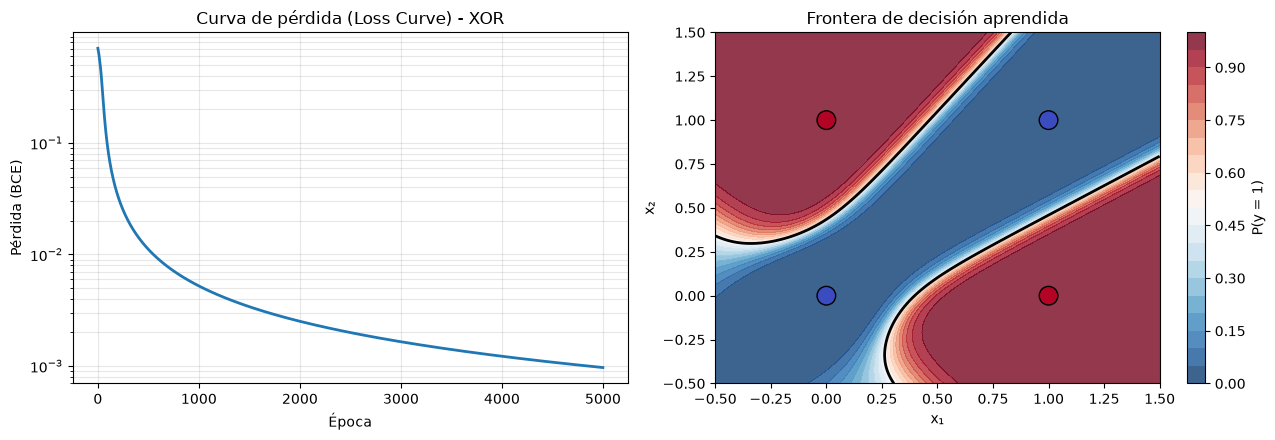

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# ---- (a) Curva de pérdida ----
axes[0].plot(history, lw=2)
axes[0].set_title("Curva de pérdida (Loss Curve) - XOR")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida (BCE)")
axes[0].set_yscale("log"); axes[0].grid(alpha=0.3, which="both")

# ---- (b) Frontera de decisión ----
xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
grid = np.vstack([xx.ravel(), yy.ravel()])               # (2, 40000)
probs = net.predict(grid, proba=True).reshape(xx.shape)

cs = axes[1].contourf(xx, yy, probs, levels=20, cmap="RdBu_r", alpha=0.8)
axes[1].contour(xx, yy, probs, levels=[0.5], colors="k", linewidths=2)
axes[1].scatter(X_xor[0], X_xor[1], c=Y_xor.ravel(), cmap="coolwarm",
                edgecolors="k", s=180, zorder=3)
plt.colorbar(cs, ax=axes[1], label="P(y = 1)")
axes[1].set_title("Frontera de decisión aprendida")
axes[1].set_xlabel("x₁"); axes[1].set_ylabel("x₂")

plt.tight_layout(); plt.show()

## 6.4 Experimentos: MSE vs. Entropía Cruzada, y efecto de $\alpha$

Verificamos empíricamente lo argumentado en la sección 4.4 y el papel de la tasa de aprendizaje.

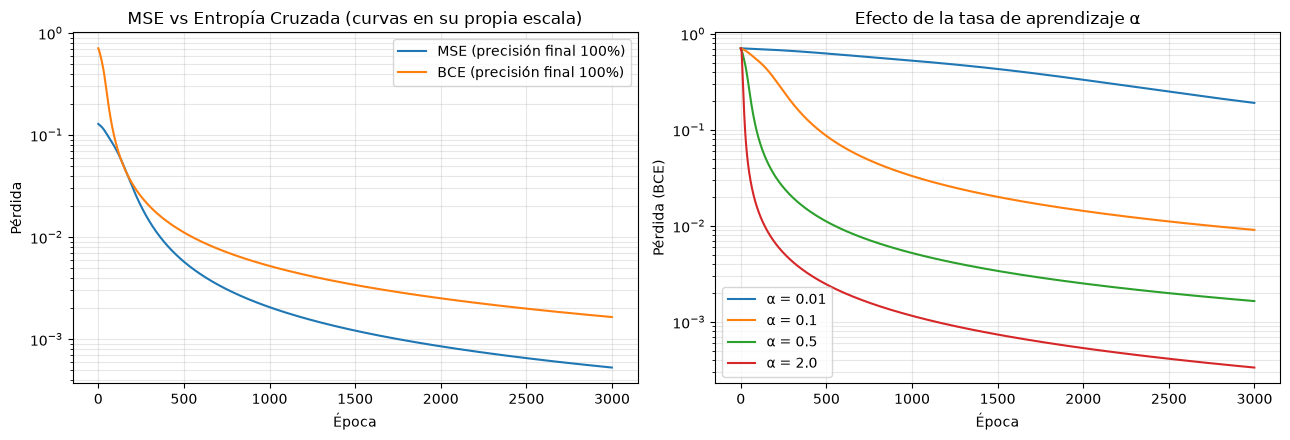

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# ---- (a) MSE vs BCE (misma red, misma inicialización) ----
for loss in ("mse", "bce"):
    n = NeuralNetwork([2, 4, 1], hidden_activation="tanh", loss=loss, seed=3)
    h = n.fit(X_xor, Y_xor, epochs=3000, lr=0.5, verbose=False)
    acc = (n.predict(X_xor) == Y_xor).mean() * 100
    axes[0].plot(h, label=f"{loss.upper()} (precisión final {acc:.0f}%)")
axes[0].set_title("MSE vs Entropía Cruzada (curvas en su propia escala)")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida"); axes[0].set_yscale("log")
axes[0].legend(); axes[0].grid(alpha=0.3, which="both")

# ---- (b) Distintas tasas de aprendizaje ----
for lr in (0.01, 0.1, 0.5, 2.0):
    n = NeuralNetwork([2, 4, 1], hidden_activation="tanh", loss="bce", seed=3)
    h = n.fit(X_xor, Y_xor, epochs=3000, lr=lr, verbose=False)
    axes[1].plot(h, label=f"α = {lr}")
axes[1].set_title("Efecto de la tasa de aprendizaje α")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Pérdida (BCE)"); axes[1].set_yscale("log")
axes[1].legend(); axes[1].grid(alpha=0.3, which="both")

plt.tight_layout(); plt.show()

## 6.5 Inspeccionando lo que aprendió la capa oculta

La capa oculta *transforma* el espacio de entrada hasta hacerlo linealmente separable; la capa de salida solo traza una "recta" en ese nuevo espacio.

In [21]:
net.forward(X_xor)
H = net.cache["A1"]                       # (4, 4): activaciones ocultas para cada ejemplo
print("Activaciones de las 4 neuronas ocultas (filas) para cada entrada (columnas):")
print("columnas = (0,0), (0,1), (1,0), (1,1)\n")
print(H.round(3))
print("\nPesos de la capa de salida W2:", net.W[2].round(3))
print("Sesgo de salida b2:", net.b[2].round(3))

Activaciones de las 4 neuronas ocultas (filas) para cada entrada (columnas):
columnas = (0,0), (0,1), (1,0), (1,1)

[[ 0.837 -0.959  1.     0.98 ]
 [-0.73  -1.     0.952 -0.978]
 [ 0.358  0.158 -0.023 -0.234]
 [ 0.278 -0.976 -0.98  -1.   ]]

Pesos de la capa de salida W2: [[-6.892  6.943  0.508 -4.36 ]]
Sesgo de salida b2: [[2.788]]


---
# 🎓 Resumen y Conclusiones

| Concepto | Idea clave | Ecuación |
|---|---|---|
| Neurona | Combinación lineal + no-linealidad | $a=g(w\cdot x+b)$ |
| Capa (vectorizada) | Matrices en lugar de bucles | $Z^{[l]}=W^{[l]}A^{[l-1]}+b^{[l]}$ |
| No-linealidad | Sin ella toda la red colapsa a una sola capa lineal | $W^{[2]}W^{[1]}=W'$ |
| Pérdida | Mide el error; MSE ↔ ruido gaussiano, CE ↔ Bernoulli | $J=\frac1m\sum\mathcal L$ |
| Dimensiones | $n^{[0]}$ = nº de características de un ejemplo; $m$ = nº de ejemplos; $W,b$ no dependen de $m$ | $X\in\mathbb R^{n^{[0]}\times m}$ |
| $\mathcal L$ vs. $J$ | $\mathcal L$ es un escalar por ejemplo y depende de todos los parámetros; $J$ es su media | $\dfrac{\partial J}{\partial\theta}=\dfrac1m\sum_i\dfrac{\partial\mathcal L^{(i)}}{\partial\theta}$ |
| Derivar respecto de un array | El gradiente de un escalar tiene la forma del array | `dX.shape == X.shape` |
| Backprop | Regla de la cadena de atrás hacia delante, reutilizando $dZ$ | $dZ^{[l-1]}=W^{[l]T}dZ^{[l]}\odot g'$ |
| Gradiente | Cómo cambia $J$ con cada parámetro | $dW^{[l]}=\frac1m dZ^{[l]}A^{[l-1]T}$ |
| Descenso | Mover los parámetros cuesta abajo | $W:=W-\alpha\,dW$ |

### Para seguir avanzando
1. **Softmax + entropía cruzada categórica** para clasificación multiclase.
2. **Mini-batches y SGD**, y optimizadores como *Momentum* y *Adam*.
3. **Regularización:** $L_2$, *dropout*, *early stopping*.
4. **Inicialización y normalización** (BatchNorm) para redes profundas.
5. Probar el notebook con datasets reales (p. ej. `make_moons` de scikit-learn, o MNIST) usando esta misma clase.

### 📝 Ejercicios propuestos
1. Cambia la activación oculta a `relu` y compara la convergencia en XOR. ¿Qué ocurre con `seed` distintas?
2. Entrena con `layer_sizes=[2, 2, 1]`. ¿Siempre converge? ¿Por qué puede quedarse atascada?
3. Añade un parámetro `l2` a `fit()` y modifica `backward()` con el término $\frac{\lambda}{m}W$.
4. Implementa **momentum**: $v := \beta v + (1-\beta)\,dW,\; W := W-\alpha v$.
5. Genera un dataset de dos "lunas" y visualiza la frontera de decisión con una red `[2, 8, 8, 1]`.